# PD correction versus initial RMS and number of beads
At fixed **calibration SNR 15**, sweep initial aberration RMS and **1–5 randomly positioned spherical beads**, measuring residual wavefront RMS after 1, 2, and 3 AO loops. The x-axis of all performance plots is **bead count**. Bead distances are saved, never used as a plot axis.

Optics, field of view, bead radius (1 um), object/reconstruction grids, diversity schedule, correction gain and optimizer options are copied from `pd_rms_snr_sweep`. Each loop acquires a new stack; cumulative fitting accounts for historical SLM corrections and uses one shared object. Every optimization screens 100 random aberrations plus zero before the exact-Hessian Newton solve.

For each bead count and trial, centers are drawn uniformly in 3D within the existing volume, with radius margins so complete beads stay inside. **Overlap is allowed**. The existing binary bead-mask function takes the union of overlapping spheres; bead count records generated spheres, even when they merge into one visible object. Every geometry is reused across initial RMS values. Each trial has one aberration direction, also reused across RMS and bead count; placement and photon noise use independent reproducible seeds.

Exposure is calibrated separately for each RMS/count/trial from its initial **aberrated z=0 image with no diversity**, then fixed through all three loops. Therefore the prescribed SNR is matched across samples; exposure and acquired-stack SNR can differ. This compares reconstruction quality at matched calibration SNR.

Checkpoints are saved after each AO loop to a separate results file, using atomic replacement. Arrays use axes `(initial RMS, bead count, trial, AO loop)` unless documented otherwise. Saved geometry includes `bead_positions_mm` (count, trial, padded bead index, xyz), full symmetric `pairwise_distances_3d_mm` matrices, and mean/minimum pairwise distances. Padding uses NaN; a single bead has no pairwise distance, so its summary distances are NaN. Diagonal entries for real beads are zero. Multiply saved distances by 1000 for micrometers.

Rerunning the main cell starts a fresh sweep rather than resuming. Existing output files are protected; choose a new `RESULTS_PATH` for another experiment.


In [17]:
from pathlib import Path
import sys
import inspect
import importlib
ROOT = Path.cwd()
while not ((ROOT / "utils").is_dir() and (ROOT / "optimization").is_dir()):
    if ROOT == ROOT.parent:
        raise RuntimeError("Run this notebook inside the repository.")
    ROOT = ROOT.parent
EXPERIMENT_DIR = ROOT / "systematic_testing" / "bead_count_sweep"
RESULTS_DIR = EXPERIMENT_DIR / "results"
FIGURES_DIR = EXPERIMENT_DIR / "figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from utils import psf, plotting, zernike
from optimization import reconstruction
from systematic_testing import correction
if "reuse_acquisitions" not in inspect.signature(correction.stack_feedback).parameters:
    importlib.reload(correction)
if "reuse_acquisitions" not in inspect.signature(correction.stack_feedback).parameters:
    raise RuntimeError(f"Update {correction.__file__} to support cumulative acquisition fits.")


In [18]:
plt.style.use("bmh")
plt.rcParams["figure.figsize"] = [548 / 72, 390 / 72]
plt.rcParams["font.size"] = 12
plt.rcParams['text.usetex'] = True
plt.rcParams["figure.dpi"] = 300

In [19]:
N_order = 3                # 3 for 3P, 2 for 2P
lambd = 1.3e-3             # Wavelength [mm]
n = 1.333                  # Refractive index
k = 2*n*np.pi/lambd        # Wavenumber
num_apt = 1.05             # Numerical aperture
f = 7.2                    # Focal length of objective (Olympus) [mm]
grid_size = 128            # BFP resolution
L_bfp = 15.12              # BFP diameter [mm]
mag = 4                    # Magnification rate from input to objective
w_0 = 3.5                  # mm
num_apt = 1.05
L_ffp = 0.0065             # FFP size [mm]
grid_ffp = 32
grid_bfp = 32
microscope = psf.Microscope(N_order = N_order,
                            lambd = lambd,
                            n = n,
                            num_apt = num_apt,
                            f = f,
                            mag = mag,
                            w_0 = w_0,
                            L_bfp = L_bfp,
                            grid_bfp = grid_bfp)

grid = psf.Centered_Square_Grid(L_ffp = L_ffp,
                                grid_ffp = grid_ffp,
                                z_level = 0)

xs, ys = grid.get_xy()


modes = [[-2,2],
         [2,2],
         [-3,3],
         [-1,3],
         [1,3],
         [3,3],
         [-4,4],
         [-2,4],
         [0,4],
         [2,4],
         [4,4],
         [-5,5],
         [-3, 5],
         [-1, 5],
         [1, 5],
         [3, 5],
         [5,5]]

In [20]:
# Sweep axes: initial pupil RMS in waves and number of generated beads; calibration SNR is fixed.
INITIAL_RMS_VALUES = np.array([0.05, 0.10, 0.15, 0.20, 0.25, 0.30])
CALIBRATION_SNR = 15.0
BEAD_COUNTS = np.arange(1, 6, dtype=int)
BEAD_SEED = 2
BEAD_RADIUS = 0.001  # mm, as in the original sweep; overlap is allowed.
NUM_TRIALS = 3
ABERRATION_SEED = 0
NOISE_SEED = 1
NUM_AO_LOOPS = 3
BACKEND = "auto"
RHO = 1e46
OPTICAL_MODE = "vector"
REUSE_ACQUISITIONS = True
CORRECTION_GAIN = 1.0
MAX_MODAL_UPDATE = 0.10
NUM_RECONSTRUCTION_PLANES = 21
NUM_STACK_Z_PLANES = 4
STACK_FOCAL_POSITIONS = np.linspace(-0.002, 0.002, NUM_STACK_Z_PLANES)
STACK_DIVERSITY_MODES_BY_LOOP = np.array([
    [[-2, 2], [0, 4], [2, 2]],
    [[-3, 3], [0, 4], [3, 3]],
    [[-4, 4], [0, 4], [4, 4]],
], dtype=int)
NUM_DIVERSITIES = STACK_DIVERSITY_MODES_BY_LOOP.shape[1]
DIVERSITY_MODES = np.array(list(dict.fromkeys(
    tuple(m) for loop_modes in STACK_DIVERSITY_MODES_BY_LOOP for m in loop_modes)))
if not 1 <= NUM_AO_LOOPS <= len(STACK_DIVERSITY_MODES_BY_LOOP):
    raise ValueError("NUM_AO_LOOPS must select between 1 and 3 scheduled loops.")
STACK_DIVERSITY_STRENGTHS = np.array([-0.10, 0.0, 0.10])
STACK_DIVERSITY_DECAY = 1.0
STACK_MIN_DIVERSITY_STRENGTH = 0.02
# Each loop runs a full optimization, with an upper bound on its inner steps.
OPTIMIZER_OPTIONS = dict(method="newton", max_iterations=50, verbose=False,
                         num_random_starts=100, random_start_rms_range=(0.005, 0.50),
                         random_start_seed=0, show_initialization_progress=True)
PRINT_OPTIMIZER_ITERATIONS = False
RESULTS_PATH = RESULTS_DIR / "pd_rms_bead_count_sweep_snr15_results.npz"
SNR_CALIBRATION = "initial_aberrated_z0_no_diversity_fixed_exposure"

z_sample_levels = np.linspace(-0.002, 0.002, 41)
z_reconstruction_levels = np.linspace(z_sample_levels[0], z_sample_levels[-1],
                                      NUM_RECONSTRUCTION_PLANES)
backend = reconstruction.get_backend(BACKEND)
for name, values in [("INITIAL_RMS_VALUES", INITIAL_RMS_VALUES),
                     ("BEAD_COUNTS", BEAD_COUNTS)]:
    if np.ndim(values) != 1 or len(values) == 0 or not np.all(np.isfinite(values)) or np.any(values <= 0):
        raise ValueError(f"{name} must contain positive finite values.")
if not np.isfinite(CALIBRATION_SNR) or CALIBRATION_SNR <= 0:
    raise ValueError("CALIBRATION_SNR must be positive and finite.")
if np.any(BEAD_COUNTS != np.floor(BEAD_COUNTS)) or len(np.unique(BEAD_COUNTS)) != len(BEAD_COUNTS):
    raise ValueError("BEAD_COUNTS must contain distinct positive integers.")
if not np.isfinite(BEAD_RADIUS) or BEAD_RADIUS <= 0:
    raise ValueError("BEAD_RADIUS must be positive and finite.")
if len(np.unique(INITIAL_RMS_VALUES)) != len(INITIAL_RMS_VALUES):
    raise ValueError("INITIAL_RMS_VALUES must not contain duplicate values.")
if not isinstance(NUM_TRIALS, (int, np.integer)) or NUM_TRIALS < 1:
    raise ValueError("NUM_TRIALS must be a positive integer.")
frames_per_loop = (len(STACK_FOCAL_POSITIONS)*NUM_DIVERSITIES
                   *len(STACK_DIVERSITY_STRENGTHS))
image_budget = NUM_AO_LOOPS*frames_per_loop
print(f"Backend: {backend}; {frames_per_loop} fresh images per AO loop, "
      f"{image_budget} images per run")
print(f"Sweep: {len(INITIAL_RMS_VALUES)*len(BEAD_COUNTS)*NUM_TRIALS} runs; "
      f"up to {OPTIMIZER_OPTIONS['max_iterations']} Newton steps per loop; calibration SNR {CALIBRATION_SNR:g}")

Backend: cpu; 36 fresh images per AO loop, 108 images per run
Sweep: 90 runs; up to 50 Newton steps per loop; calibration SNR 15


In [21]:
# Draw independent random 3D samples; allow overlaps and reuse each geometry across RMS.
max_beads = int(np.max(BEAD_COUNTS))
x_coordinates, y_coordinates = grid.get_xy()
geometry_bounds_mm = np.array([
    [np.min(x_coordinates)+BEAD_RADIUS, np.max(x_coordinates)-BEAD_RADIUS],
    [np.min(y_coordinates)+BEAD_RADIUS, np.max(y_coordinates)-BEAD_RADIUS],
    [np.min(z_sample_levels)+BEAD_RADIUS, np.max(z_sample_levels)-BEAD_RADIUS],
])
if np.any(geometry_bounds_mm[:, 1] < geometry_bounds_mm[:, 0]):
    raise ValueError("The bead radius is too large for the current sample volume.")
bead_positions_mm = np.full((len(BEAD_COUNTS), NUM_TRIALS, max_beads, 3), np.nan)
pairwise_distances_3d_mm = np.full((len(BEAD_COUNTS), NUM_TRIALS, max_beads, max_beads), np.nan)
mean_pairwise_distance_3d_mm = np.full((len(BEAD_COUNTS), NUM_TRIALS), np.nan)
min_pairwise_distance_3d_mm = np.full((len(BEAD_COUNTS), NUM_TRIALS), np.nan)
bead_samples = {}
for ci, count in enumerate(BEAD_COUNTS):
    count = int(count)
    for trial in range(NUM_TRIALS):
        geometry_rng = np.random.default_rng(np.random.SeedSequence([BEAD_SEED, count, trial]))
        centers = geometry_rng.uniform(geometry_bounds_mm[:, 0], geometry_bounds_mm[:, 1],
                                       size=(count, 3))
        bead_positions_mm[ci, trial, :count] = centers
        distances = np.linalg.norm(centers[:, None, :]-centers[None, :, :], axis=-1)
        pairwise_distances_3d_mm[ci, trial, :count, :count] = distances
        if count > 1:
            pairs = distances[np.triu_indices(count, k=1)]
            mean_pairwise_distance_3d_mm[ci, trial] = pairs.mean()
            min_pairwise_distance_3d_mm[ci, trial] = pairs.min()
        bead_samples[(ci, trial)] = psf.bead_img_3D(
            grid, z_sample_levels, centers[:, 0], centers[:, 1], centers[:, 2],
            np.full(count, BEAD_RADIUS))
print(f"Generated {len(bead_samples)} random samples, with overlap allowed. Distances will be saved only.")


Generated 15 random samples, with overlap allowed. Distances will be saved only.


In [22]:
# Calibrate from the initial aberrated z=0 image with no diversity; then fix exposure.
# Global shot-noise SNR = sqrt(sum((exposure*I)**2) / sum(exposure*I)).
# I is the single z=0, zero-diversity image, before any SLM correction.
wavefront_directions = np.array([
    np.random.default_rng(np.random.SeedSequence([ABERRATION_SEED, trial])).normal(size=len(modes))
    for trial in range(NUM_TRIALS)])
# Fixed single-mode bases; normalize their pupil RMS as in the previous probe design.
diversity_basis_strengths = np.zeros((NUM_TRIALS, NUM_AO_LOOPS,
                                      NUM_DIVERSITIES, len(DIVERSITY_MODES)))
for loop in range(NUM_AO_LOOPS):
    for probe, probe_mode in enumerate(STACK_DIVERSITY_MODES_BY_LOOP[loop]):
        unit_aberration = zernike.RMSAberration(
            modes=[probe_mode], raw_strengths=[1.0],
            RMS_desired=1.0, alpha=microscope.alpha)
        mode_index = np.flatnonzero(np.all(DIVERSITY_MODES == probe_mode, axis=1))[0]
        diversity_basis_strengths[:, loop, probe, mode_index] = unit_aberration.strengths[0]
loop_diversity_strengths = np.array([
    np.sign(STACK_DIVERSITY_STRENGTHS)*np.maximum(
        np.abs(STACK_DIVERSITY_STRENGTHS)*STACK_DIVERSITY_DECAY**loop,
        np.minimum(np.abs(STACK_DIVERSITY_STRENGTHS), STACK_MIN_DIVERSITY_STRENGTH))
    for loop in range(NUM_AO_LOOPS)])
diversity_schedules = [
    [[zernike.Aberration(DIVERSITY_MODES, basis*float(bias))
      for basis in diversity_basis_strengths[trial, loop]
      for bias in loop_diversity_strengths[loop]]
     for loop in range(NUM_AO_LOOPS)] for trial in range(NUM_TRIALS)]
initial_focal_z = np.repeat(STACK_FOCAL_POSITIONS,
                            NUM_DIVERSITIES*len(STACK_DIVERSITY_STRENGTHS))
exposures = np.full((len(INITIAL_RMS_VALUES), len(BEAD_COUNTS), NUM_TRIALS), np.nan)
initial_clean_stacks = {}
calibration_clean_images = {}
with tqdm(total=len(INITIAL_RMS_VALUES)*len(BEAD_COUNTS)*NUM_TRIALS,
          desc="Calibrating aberrated bead samples", unit="case") as calibration_progress:
    for ri, rms in enumerate(INITIAL_RMS_VALUES):
        for trial in range(NUM_TRIALS):
            truth = zernike.RMSAberration(
                modes=modes, raw_strengths=wavefront_directions[trial],
                RMS_desired=float(rms), alpha=microscope.alpha)
            for ci, bead_count in enumerate(BEAD_COUNTS):
                sample = bead_samples[(ci, trial)]
                calibration_image = microscope.compute_image_3D(
                    sample, truth, [0.0], mode=OPTICAL_MODE, diversities=None)[3]
                calibration_clean_images[(ri, ci, trial)] = calibration_image
                exposures[ri, ci, trial] = correction.exposure_for_snr(
                    calibration_image, CALIBRATION_SNR)
                clean = microscope.compute_image_3D(
                    sample, truth, initial_focal_z, mode=OPTICAL_MODE,
                    diversities=[probe for _ in STACK_FOCAL_POSITIONS
                                 for probe in diversity_schedules[trial][0]])[3]
                initial_clean_stacks[(ri, ci, trial)] = clean
                calibration_progress.update(1)
print("Aberrated z=0, zero-diversity calibration complete; first-loop clean images cached for reuse.")


def expected_stack_snr(clean_images, exposure):
    """Expected global RMS shot-noise SNR, not a noisy realization's estimate."""
    clean = np.maximum(np.asarray(clean_images, dtype=float), 0)
    peak = float(clean.max())
    if peak == 0:
        return 0.0
    unit = clean/peak
    return float(np.sqrt(exposure*peak*np.sum(unit**2)/unit.sum()))


class SweepSLM(correction.SimulatedSLM):
    """Reuse cached PD images for loop 1 and record actual stack SNR each loop."""
    def __init__(self, *args, initial_clean, **kwargs):
        super().__init__(*args, **kwargs)
        self.initial_clean = initial_clean
        self.acquisition_snrs = []

    def acquire(self, focal_z_levels, diversities=None):
        if self.images_taken == 0:
            clean = self.initial_clean
        else:
            clean = self.microscope.compute_image_3D(
                self.sample, self._residual(), focal_z_levels,
                diversities=diversities, mode=self.optical_mode)[3]
        if (not np.all(np.isfinite(clean)) or
                clean.min() < -1e-12*max(float(clean.max()), 0)):
            raise ValueError("Simulated images must be finite and nonnegative.")
        counts = self.rng.poisson(self.exposure*np.maximum(clean, 0))
        self.images_taken += len(counts)
        self.photons_detected += int(counts.sum())
        self.acquisition_snrs.append(expected_stack_snr(clean, self.exposure))
        return counts/self.exposure


Calibrating aberrated bead samples:   0%|          | 0/90 [00:00<?, ?case/s]

Calibrating aberrated bead samples: 100%|██████████| 90/90 [00:41<00:00,  2.17case/s]

Aberrated z=0, zero-diversity calibration complete; first-loop clean images cached for reuse.


## Preview before the sweep
Inspect the random bead samples, aberration strengths, and noisy diversity frames using the existing plotting helpers. The previews use independent noise draws and do not spend the correction image budget. Performance plots show bead count; pairwise distances remain available in the checkpoint data.


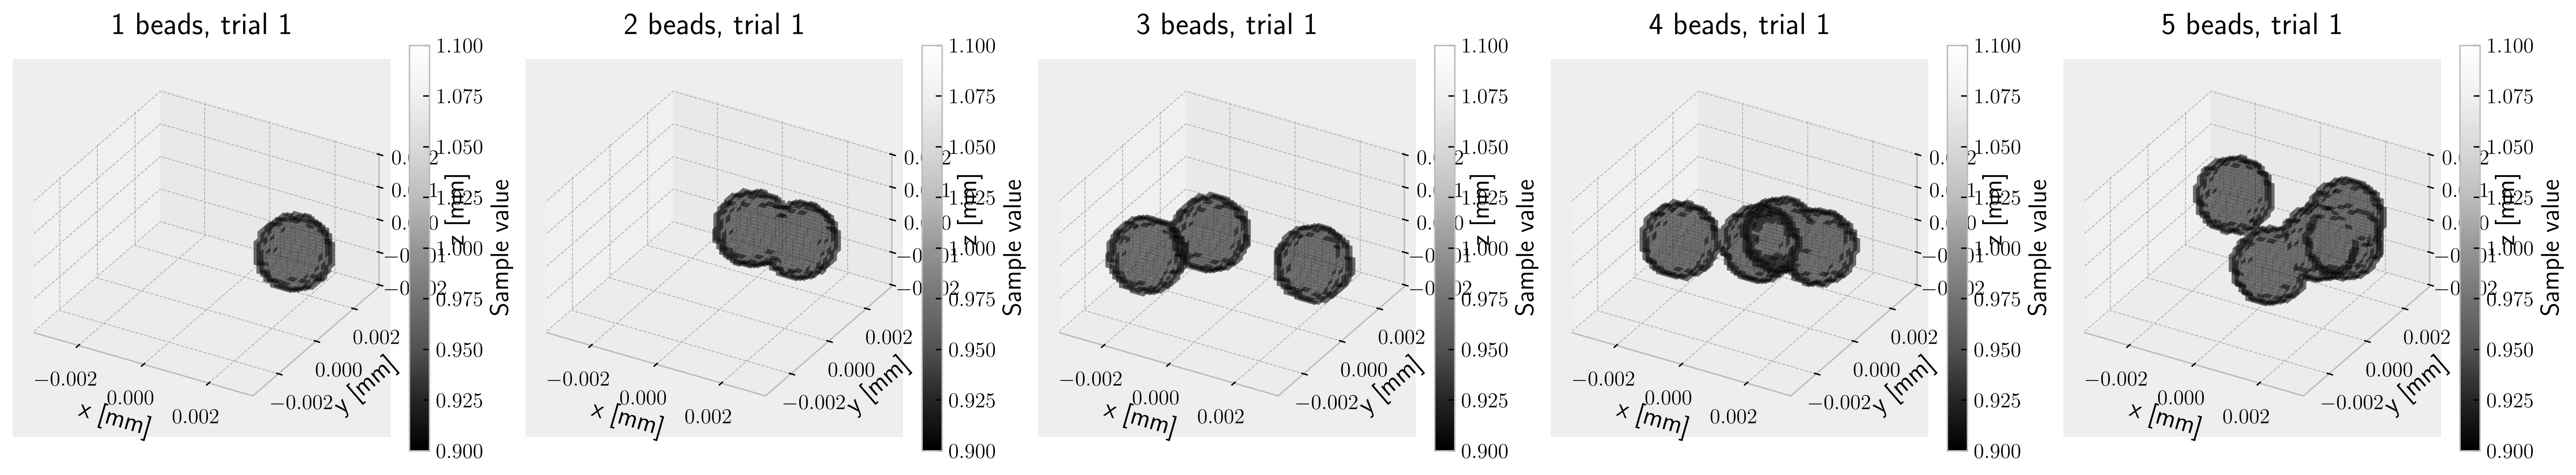

In [23]:
PREVIEW_TRIAL = 0
PREVIEW_FOCUS_INDEX = int(np.argmin(np.abs(STACK_FOCAL_POSITIONS)))
PREVIEW_RMS_INDEX = len(INITIAL_RMS_VALUES)//2
PREVIEW_BEAD_INDEX = len(BEAD_COUNTS)//2
if not 0 <= PREVIEW_TRIAL < NUM_TRIALS:
    raise ValueError("PREVIEW_TRIAL must select a configured trial.")
preview_focus = float(STACK_FOCAL_POSITIONS[PREVIEW_FOCUS_INDEX])
fig = plt.figure(figsize=(4*len(BEAD_COUNTS), 4.6), layout="constrained")
for ci, count in enumerate(BEAD_COUNTS):
    ax = fig.add_subplot(1, len(BEAD_COUNTS), ci+1, projection="3d")
    plotting.plot_sample_3D(bead_samples[(ci, PREVIEW_TRIAL)], ax=ax, show=False)
    ax.set_title(f"{count} beads, trial {PREVIEW_TRIAL+1}", pad=14)
plt.show()


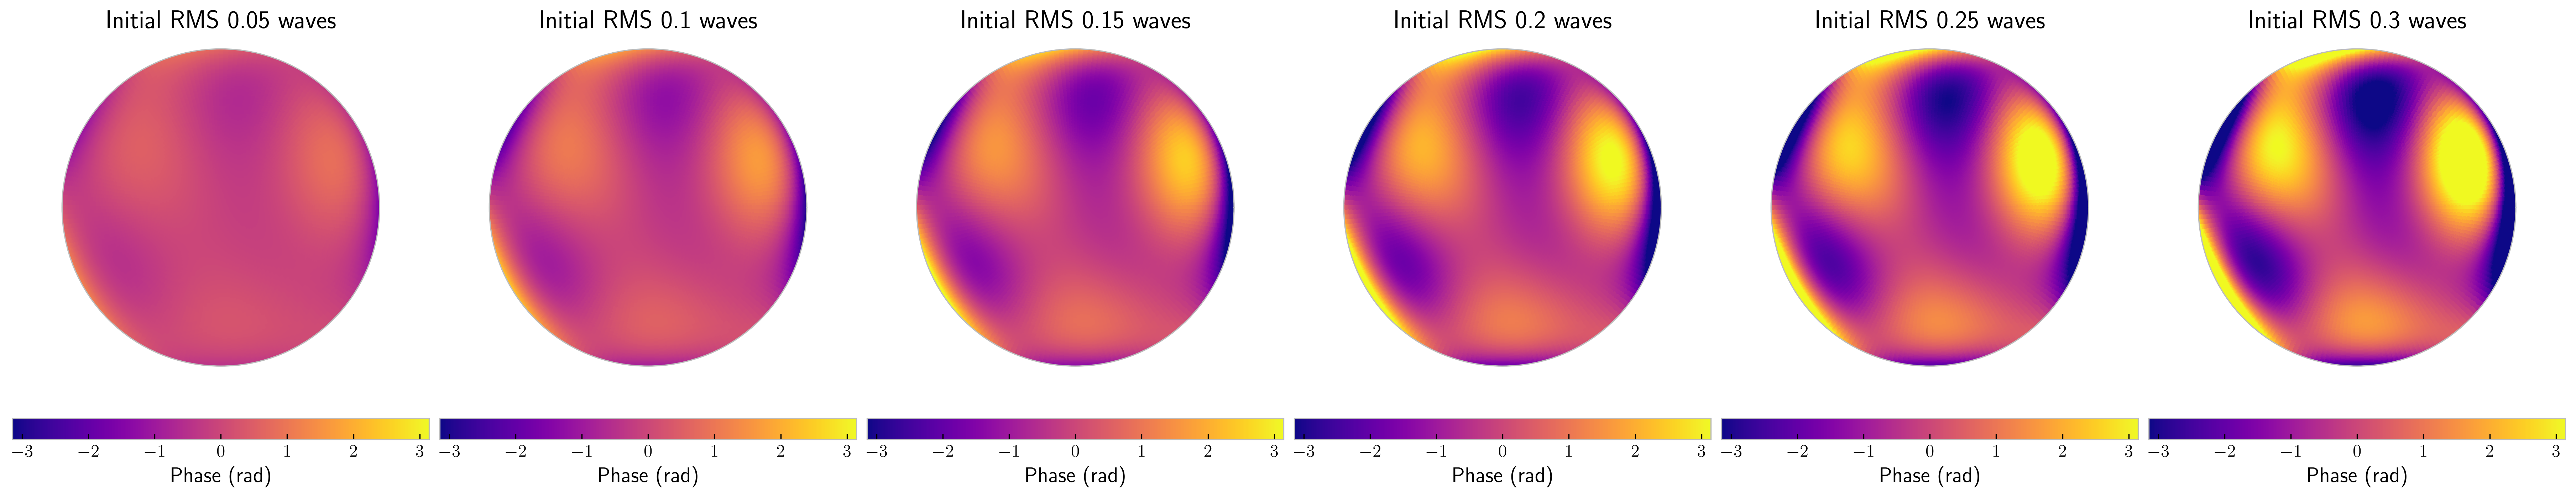

In [24]:
# Same arbitrary modal mixture at each prescribed RMS, as in the main sweep.
preview_truths = [zernike.RMSAberration(
    modes=modes, raw_strengths=wavefront_directions[PREVIEW_TRIAL],
    RMS_desired=float(rms), alpha=microscope.alpha) for rms in INITIAL_RMS_VALUES]
phase_rho, phase_phi = np.meshgrid(np.linspace(0, 1, 101),
                                 np.linspace(0, 2*np.pi, 101), indexing="ij")
phase_theta = np.arcsin(phase_rho*np.sin(microscope.alpha))
preview_phase_limit = max(np.pi, max(float(np.max(np.abs(
    a.construct_map(microscope.alpha)(phase_theta, phase_phi)))) for a in preview_truths))
fig = plt.figure(figsize=(4*len(preview_truths), 4.8), layout="constrained")
phase_layout = fig.add_gridspec(2, len(preview_truths), height_ratios=[1, .07])
for i, aberration in enumerate(preview_truths):
    ax = fig.add_subplot(phase_layout[0, i], projection="polar")
    plotting.zernike_plot(aberration.construct_map(microscope.alpha), microscope.alpha,
                         res=201, ax=ax, show=False, colorbar=True)
    ax.set_title(f"Initial RMS {INITIAL_RMS_VALUES[i]:g} waves", pad=14)

plt.show()

In [25]:
# All three first-loop diversity modes at one configured focus; re-use clean simulations across bead counts.
preview_diversities = diversity_schedules[PREVIEW_TRIAL][0]
preview_focal_z = np.full(len(preview_diversities), preview_focus)
preview_images = {}
preview_frames_per_focus = len(preview_diversities)
preview_frame_slice = slice(PREVIEW_FOCUS_INDEX*preview_frames_per_focus,
                            (PREVIEW_FOCUS_INDEX+1)*preview_frames_per_focus)
preview_x, preview_y = grid.get_xy()
for ri, aberration in enumerate(preview_truths):
    for ci, count in enumerate(BEAD_COUNTS):
        clean = initial_clean_stacks[(ri, ci, PREVIEW_TRIAL)][preview_frame_slice]
        exposure = float(exposures[ri, ci, PREVIEW_TRIAL])
        preview_rng = np.random.default_rng(np.random.SeedSequence(
            [NOISE_SEED, ri, int(count), PREVIEW_TRIAL, 9901]))
        preview_images[(ri, ci)] = preview_rng.poisson(
            exposure*np.maximum(clean, 0))/exposure
print(f"Preview images ready at focus {preview_focus*1000:+.3f} um.")

# Existing plotting helper, with dedicated colorbar space and compact shared labels.
from matplotlib.ticker import MaxNLocator, FormatStrFormatter
def plot_preview_grid(image_rows, row_labels, column_labels, title):
    image_rows = np.asarray(image_rows)
    nr, nc = image_rows.shape[:2]
    fig = plt.figure(figsize=(3*nc+.8, 2.8*nr+.8), layout="constrained")
    layout = fig.add_gridspec(nr, nc+1, width_ratios=[1]*nc+[.06])
    axes = np.array([[fig.add_subplot(layout[r, c]) for c in range(nc)] for r in range(nr)])
    plotting.plot_many_intensity(axes, preview_x, preview_y,
                                image_rows.reshape(-1, len(preview_x), len(preview_y)),
                                normalize=False)
    for r in range(nr):
        for c in range(nc):
            ax = axes[r, c]
            ax.tick_params(axis="both", labelrotation=0, labelbottom=r == nr-1, labelleft=c == 0)
            ax.xaxis.set_major_locator(MaxNLocator(3))
            ax.yaxis.set_major_locator(MaxNLocator(3))
            ax.xaxis.set_major_formatter(FormatStrFormatter("%.3f"))
            ax.yaxis.set_major_formatter(FormatStrFormatter("%.3f"))
            ax.set_title(column_labels[c] if r == 0 else "", pad=10)
            ax.set_xlabel("x [mm]" if r == nr-1 else "")
            ax.set_ylabel(row_labels[r]+"\ny [mm]" if c == 0 else "")
    fig.suptitle(title, fontsize=12)
    fig.colorbar(axes[0, 0].images[0], cax=fig.add_subplot(layout[:, -1]),
                 label="Measured intensity (shared raw scale)")
    plt.show()
    return fig, axes

Preview images ready at focus +0.667 um.


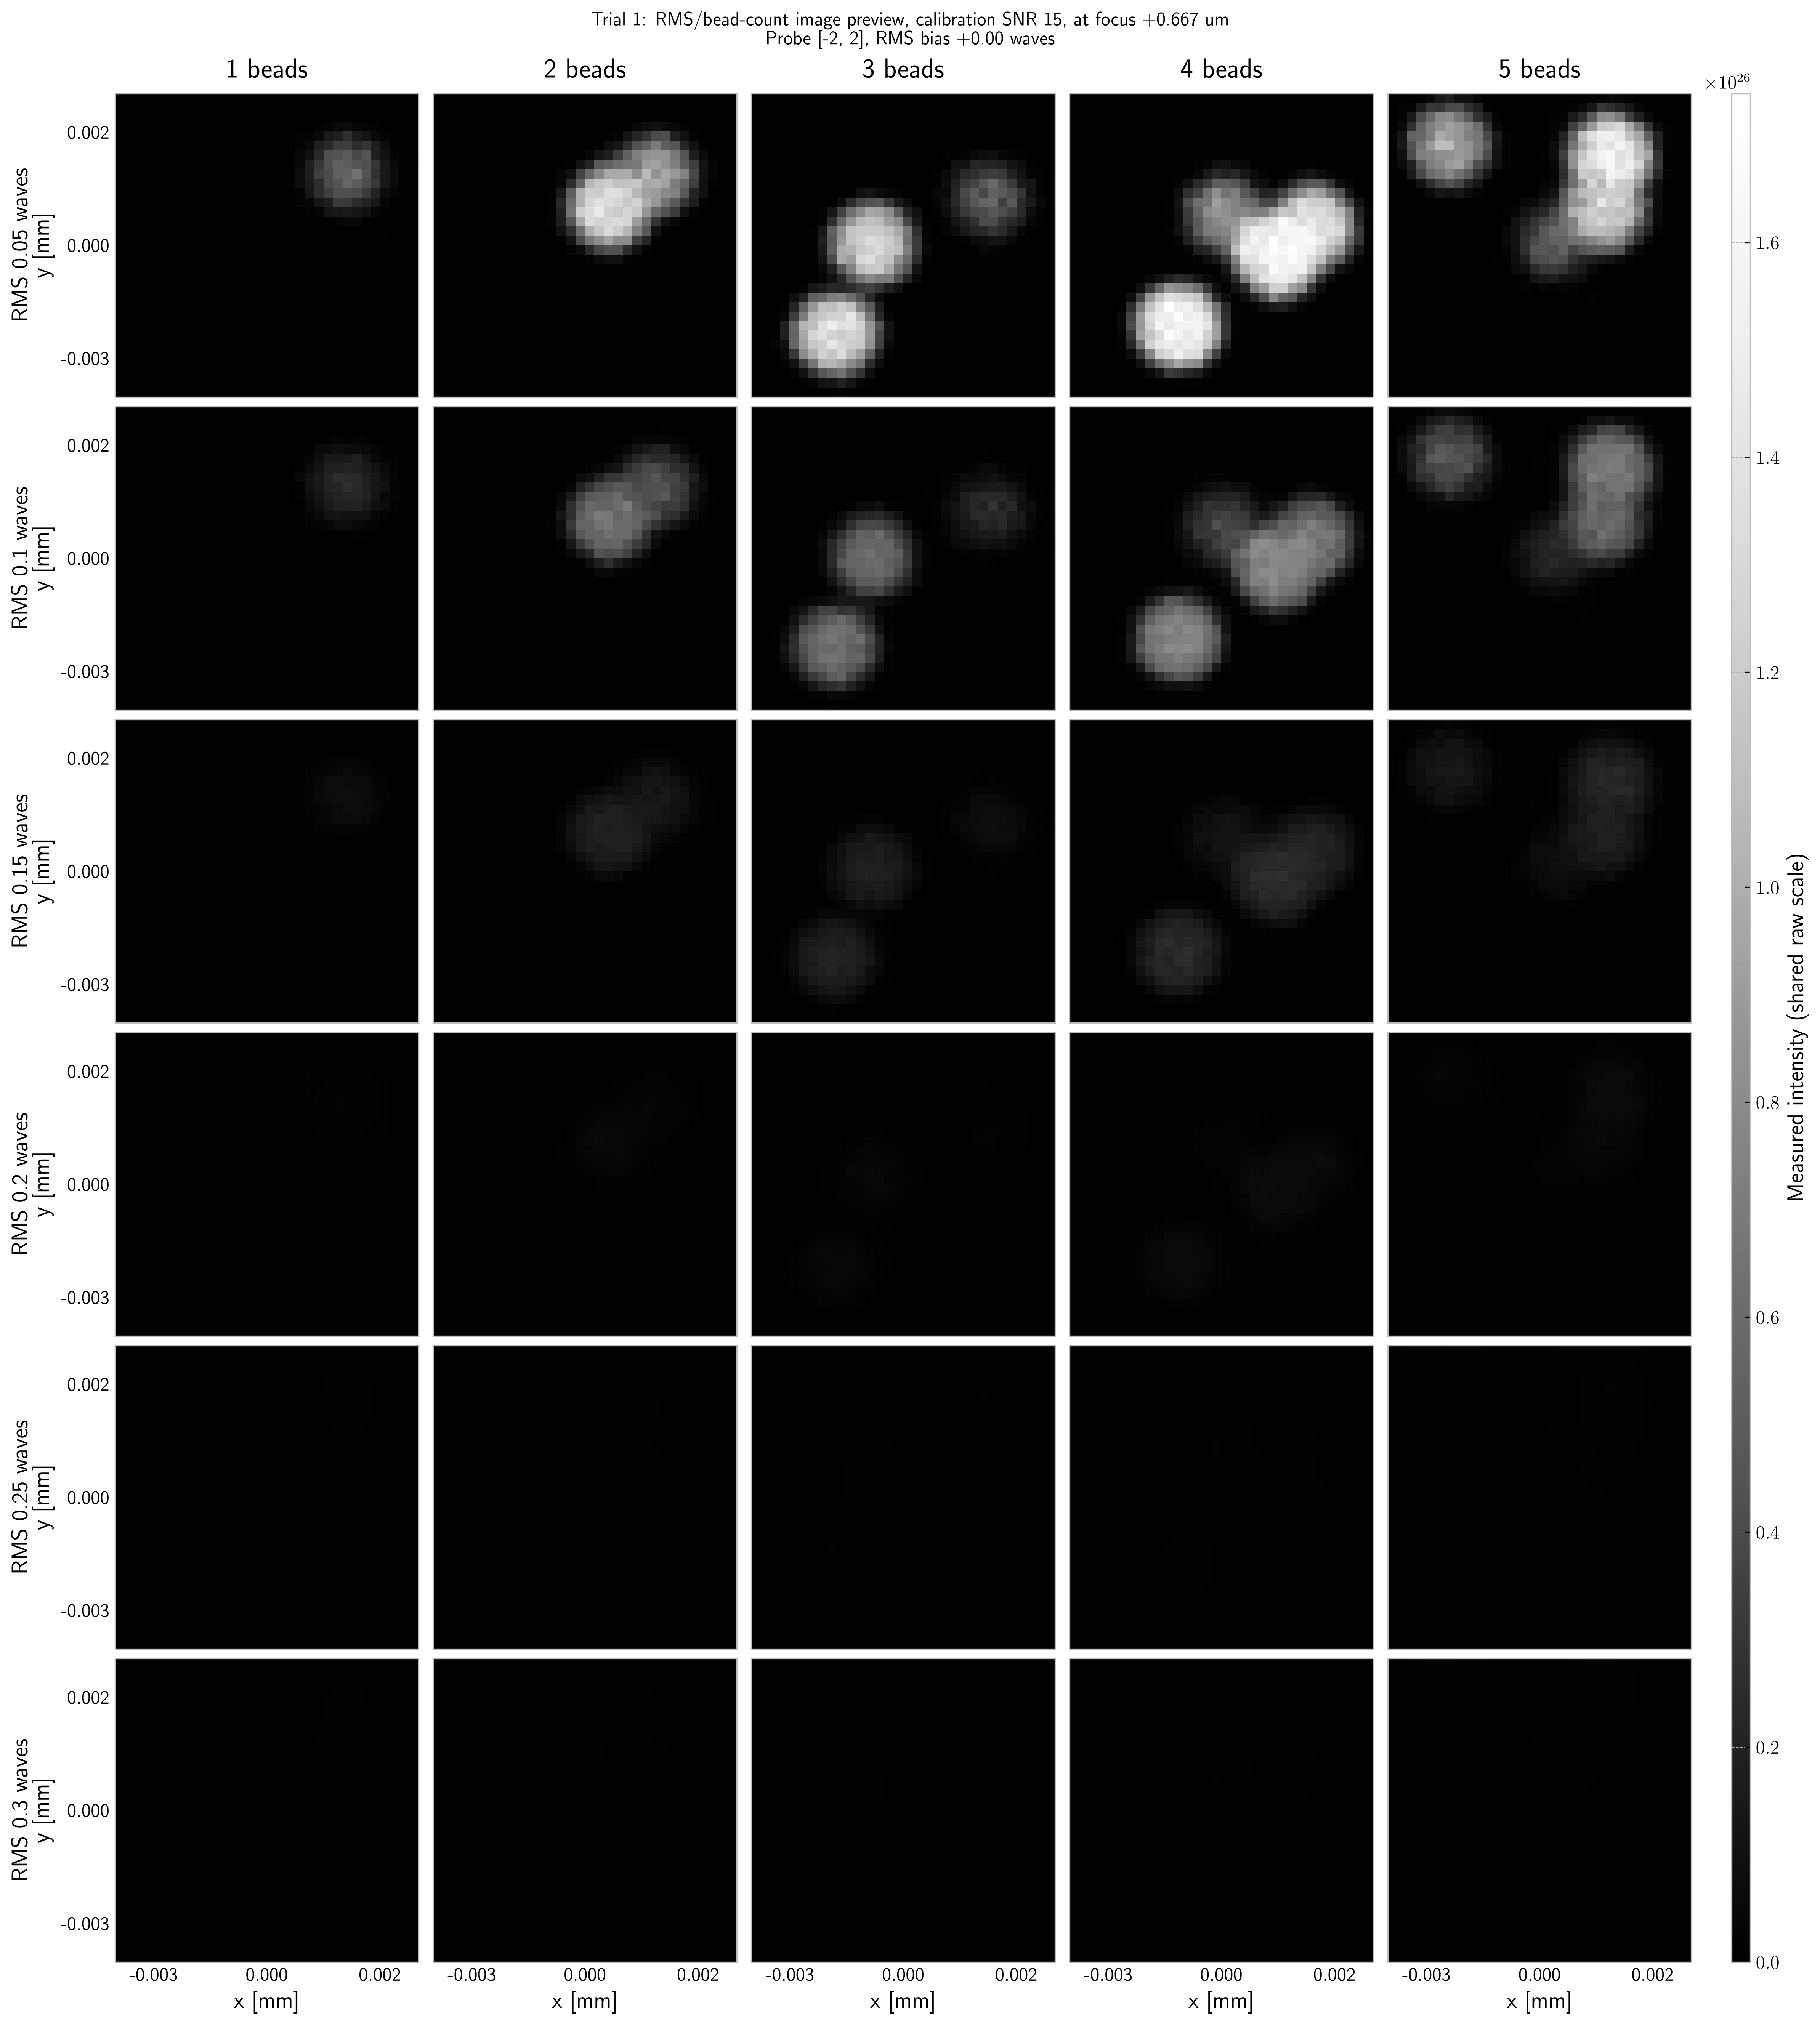

(<Figure size 4740x5280 with 31 Axes>,
 array([[<Axes: title={'center': '1 beads'}, ylabel='RMS 0.05 waves\ny [mm]'>,
         <Axes: title={'center': '2 beads'}>,
         <Axes: title={'center': '3 beads'}>,
         <Axes: title={'center': '4 beads'}>,
         <Axes: title={'center': '5 beads'}>],
        [<Axes: ylabel='RMS 0.1 waves\ny [mm]'>, <Axes: >, <Axes: >,
         <Axes: >, <Axes: >],
        [<Axes: ylabel='RMS 0.15 waves\ny [mm]'>, <Axes: >, <Axes: >,
         <Axes: >, <Axes: >],
        [<Axes: ylabel='RMS 0.2 waves\ny [mm]'>, <Axes: >, <Axes: >,
         <Axes: >, <Axes: >],
        [<Axes: ylabel='RMS 0.25 waves\ny [mm]'>, <Axes: >, <Axes: >,
         <Axes: >, <Axes: >],
        [<Axes: xlabel='x [mm]', ylabel='RMS 0.3 waves\ny [mm]'>,
         <Axes: xlabel='x [mm]'>, <Axes: xlabel='x [mm]'>,
         <Axes: xlabel='x [mm]'>, <Axes: xlabel='x [mm]'>]], dtype=object))

In [26]:
# Show the same probe for every RMS/bead-count combination.
preview_bias_index = int(np.argmin(np.abs(STACK_DIVERSITY_STRENGTHS)))
preview_overview = np.array([[preview_images[(ri, si)][preview_bias_index]
                             for si in range(len(BEAD_COUNTS))]
                            for ri in range(len(INITIAL_RMS_VALUES))])
plot_preview_grid(
    preview_overview, [f"RMS {r:g} waves" for r in INITIAL_RMS_VALUES],
    [f"{count} beads" for count in BEAD_COUNTS],
    f"Trial {PREVIEW_TRIAL+1}: RMS/bead-count image preview, calibration SNR {CALIBRATION_SNR:g}, at focus {preview_focus*1000:+.3f} um\n"
    f"Probe {STACK_DIVERSITY_MODES_BY_LOOP[0, 0].tolist()}, RMS bias {STACK_DIVERSITY_STRENGTHS[preview_bias_index]:+.2f} waves")

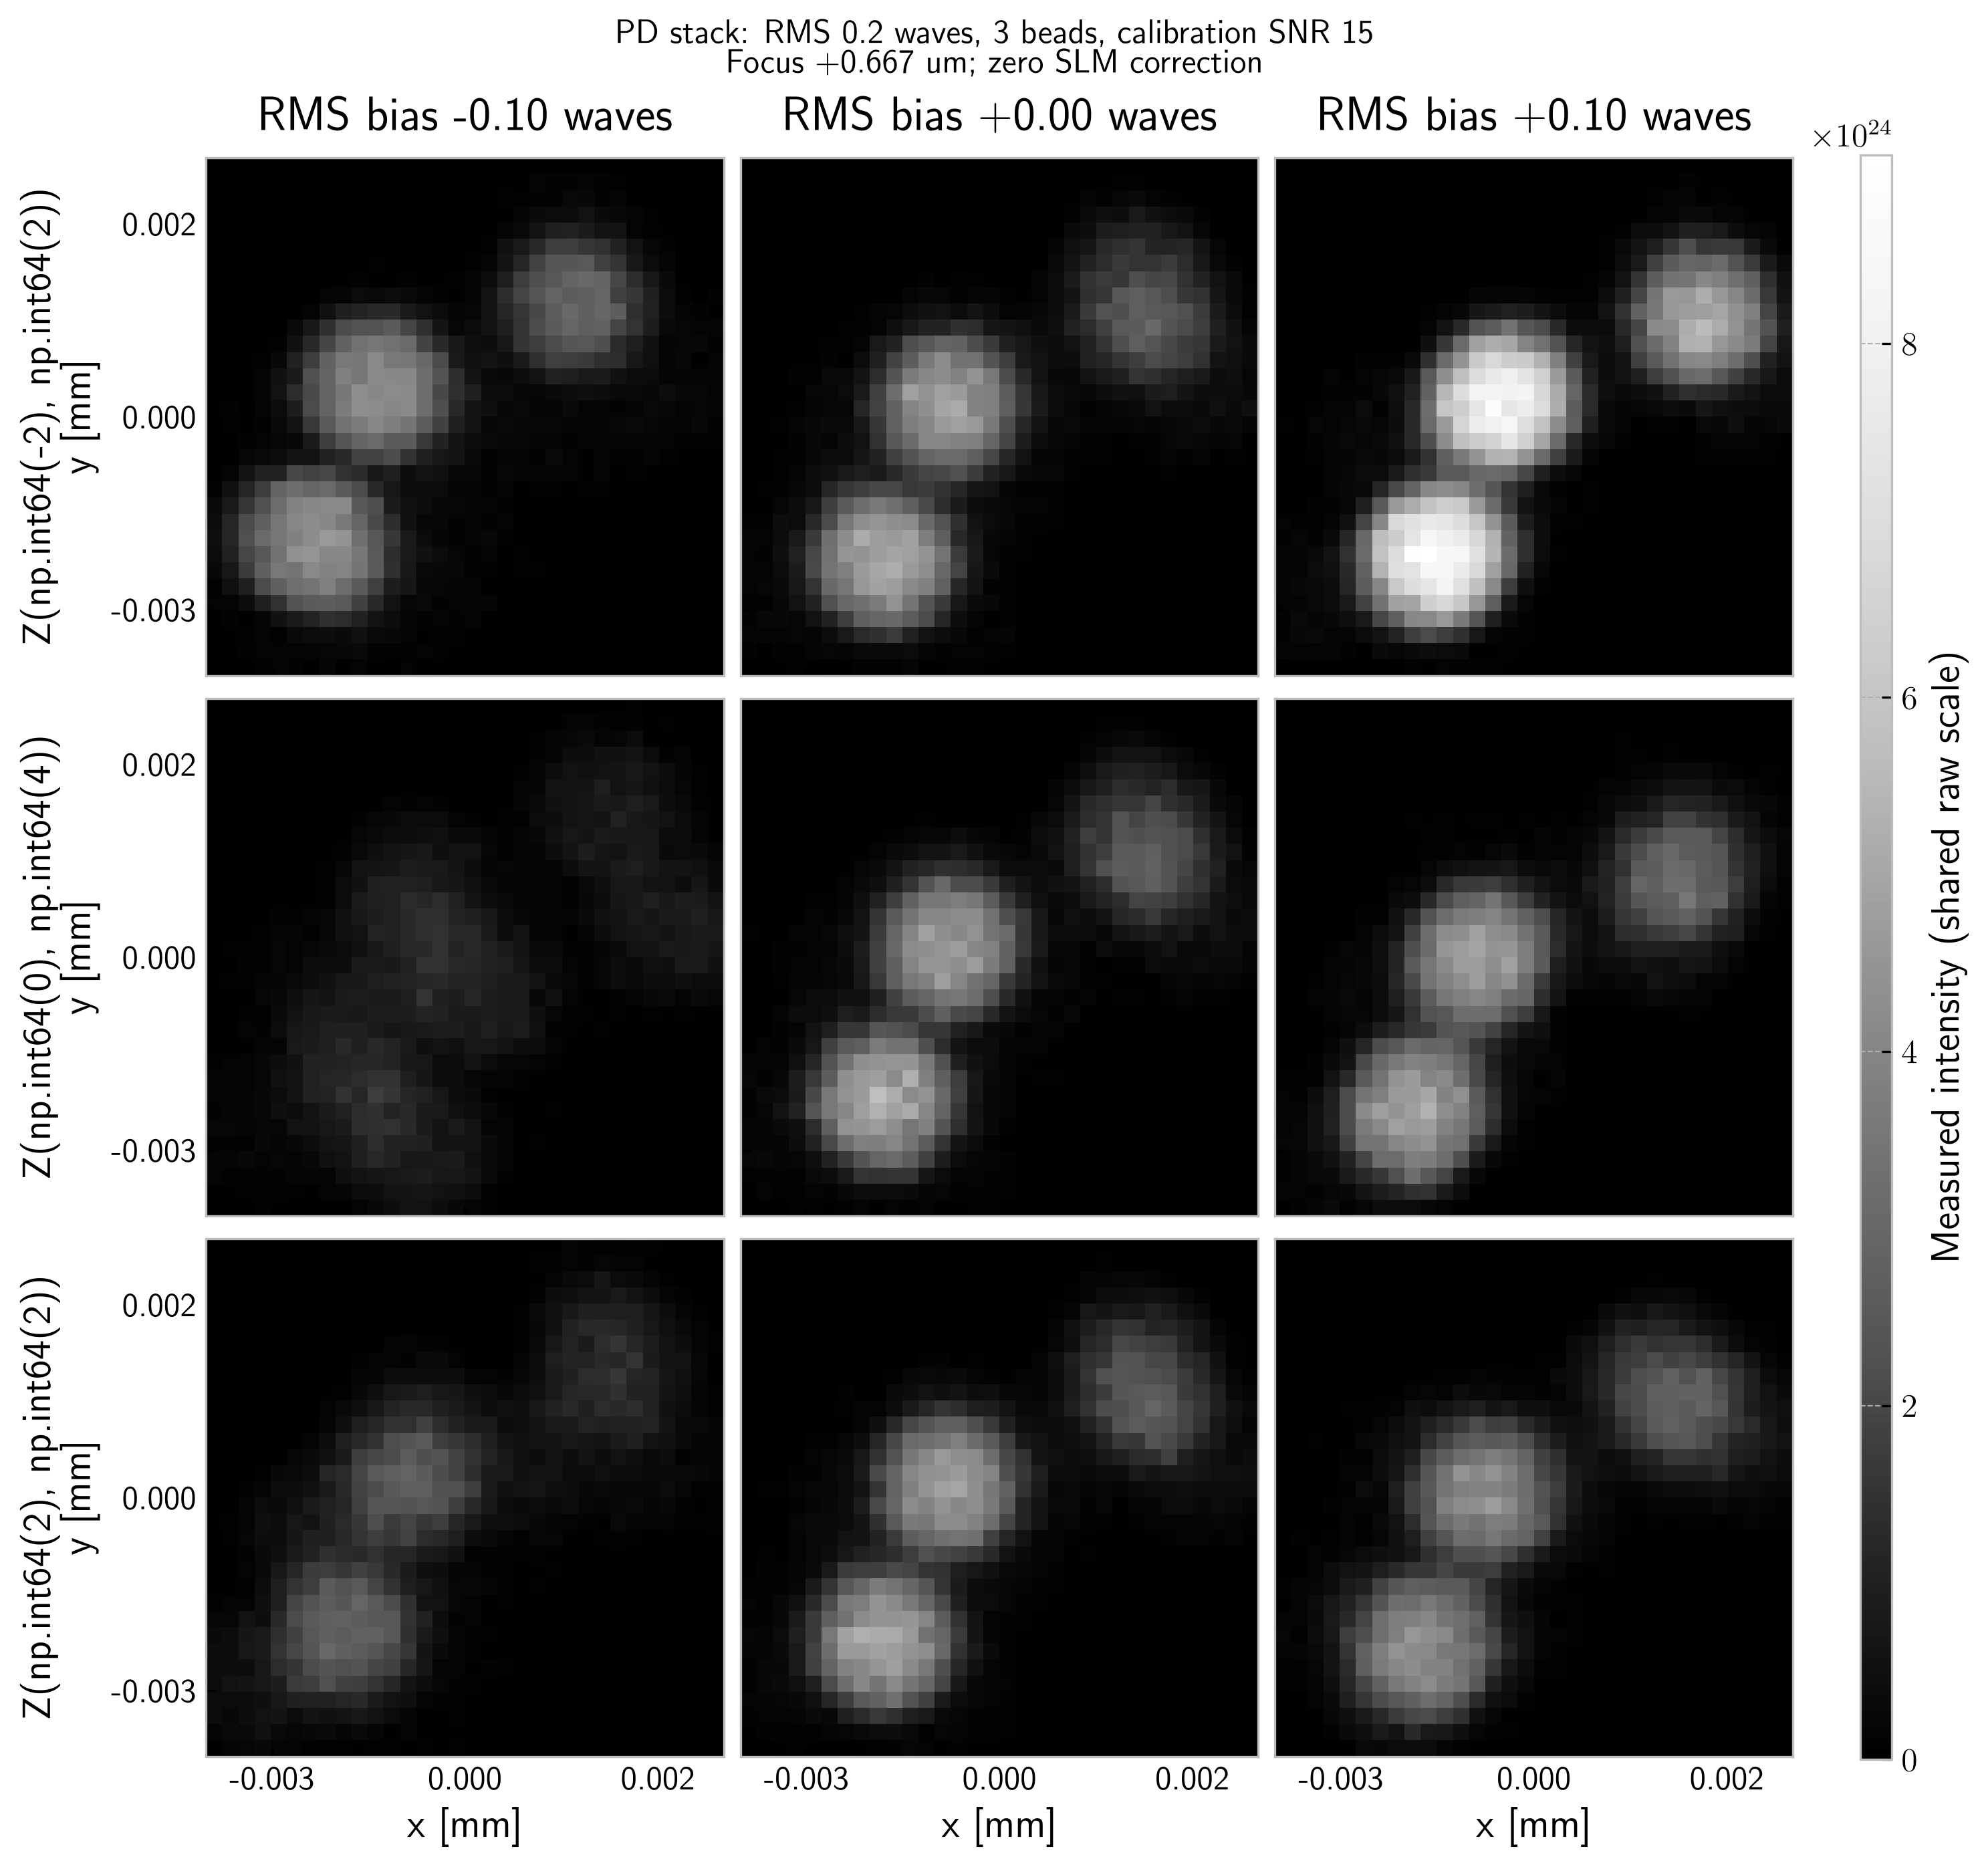

(<Figure size 2940x2760 with 10 Axes>,
 array([[<Axes: title={'center': 'RMS bias -0.10 waves'}, ylabel='Z(np.int64(-2), np.int64(2))\ny [mm]'>,
         <Axes: title={'center': 'RMS bias +0.00 waves'}>,
         <Axes: title={'center': 'RMS bias +0.10 waves'}>],
        [<Axes: ylabel='Z(np.int64(0), np.int64(4))\ny [mm]'>, <Axes: >,
         <Axes: >],
        [<Axes: xlabel='x [mm]', ylabel='Z(np.int64(2), np.int64(2))\ny [mm]'>,
         <Axes: xlabel='x [mm]'>, <Axes: xlabel='x [mm]'>]], dtype=object))

In [27]:
# Inspect every diversity image for one chosen RMS/bead-count pair.
preview_selected = preview_images[(PREVIEW_RMS_INDEX, PREVIEW_BEAD_INDEX)].reshape(
    NUM_DIVERSITIES, len(STACK_DIVERSITY_STRENGTHS), len(preview_x), len(preview_y))
plot_preview_grid(
    preview_selected,
    [f"Z{tuple(m)}" for m in STACK_DIVERSITY_MODES_BY_LOOP[0]],
    [f"RMS bias {b:+.2f} waves" for b in STACK_DIVERSITY_STRENGTHS],
    f"PD stack: RMS {INITIAL_RMS_VALUES[PREVIEW_RMS_INDEX]:g} waves, "
    f"{BEAD_COUNTS[PREVIEW_BEAD_INDEX]} beads, calibration SNR {CALIBRATION_SNR:g}\n"
    f"Focus {preview_focus*1000:+.3f} um; zero SLM correction")

In [28]:
# Save after each completed AO loop. Atomic replacement preserves the last good file.
import os
import tempfile

def save_sweep_checkpoint():
    destination = RESULTS_PATH.resolve()
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = None
    try:
        with tempfile.NamedTemporaryFile(mode="wb", dir=destination.parent,
                                         prefix=destination.name+".", suffix=".tmp",
                                         delete=False) as stream:
            temporary = Path(stream.name)
            np.savez_compressed(
                stream, initial_rms=INITIAL_RMS_VALUES, target_snr=CALIBRATION_SNR, bead_counts=BEAD_COUNTS,
                bead_seed=BEAD_SEED, bead_radius_mm=BEAD_RADIUS,
                bead_positions_mm=bead_positions_mm, pairwise_distances_3d_mm=pairwise_distances_3d_mm,
                mean_pairwise_distance_3d_mm=mean_pairwise_distance_3d_mm,
                min_pairwise_distance_3d_mm=min_pairwise_distance_3d_mm,
                geometry_bounds_mm=geometry_bounds_mm,
                result_axes=np.array(["initial_rms", "bead_count", "trial", "ao_loop"]),
                snr_calibration=SNR_CALIBRATION, calibration_z=0.0,
                calibration_diversity_strength=0.0, acquisition_snr=acquisition_snr,
                ao_loops=np.arange(1, NUM_AO_LOOPS+1), residual_rms=residual_rms,
                completed=np.isfinite(residual_rms),
                optimizer_loss=optimizer_loss, optimizer_steps=optimizer_steps,
                optimizer_success=optimizer_success, images_taken=images_taken,
                fit_image_count=fit_image_count, reuse_acquisitions=REUSE_ACQUISITIONS,
                slm_strengths=slm_strengths, truth_strengths=truth_strengths, modes=np.asarray(modes),
                exposures=exposures, wavefront_directions=wavefront_directions,
                rho=RHO, correction_gain=CORRECTION_GAIN, max_modal_update=MAX_MODAL_UPDATE,
                focal_positions=STACK_FOCAL_POSITIONS, diversity_modes=DIVERSITY_MODES,
                diversity_modes_by_loop=STACK_DIVERSITY_MODES_BY_LOOP[:NUM_AO_LOOPS],
                num_diversities=NUM_DIVERSITIES,
                diversity_basis_strengths=diversity_basis_strengths,
                loop_diversity_strengths=loop_diversity_strengths,
                diversity_strengths=STACK_DIVERSITY_STRENGTHS, diversity_decay=STACK_DIVERSITY_DECAY,
                min_diversity_strength=STACK_MIN_DIVERSITY_STRENGTH,
                sample_z=z_sample_levels, reconstruction_z=z_reconstruction_levels,
                aberration_seed=ABERRATION_SEED, noise_seed=NOISE_SEED,
                max_optimizer_iterations=OPTIMIZER_OPTIONS['max_iterations'], backend=backend,
                num_random_starts=OPTIMIZER_OPTIONS['num_random_starts'],
                random_start_rms_range=OPTIMIZER_OPTIONS['random_start_rms_range'],
                random_start_seed=OPTIMIZER_OPTIONS['random_start_seed'])
            stream.flush()
            os.fsync(stream.fileno())
        os.replace(temporary, destination)
    finally:
        if temporary is not None:
            temporary.unlink(missing_ok=True)

# Reload partial results with np.load(RESULTS_PATH, allow_pickle=False).
# 'completed' identifies saved loops; unfinished residuals remain NaN.


In [30]:
# This starts a fresh sweep; choose a new RESULTS_PATH if you already ran it.
if RESULTS_PATH.exists():
    raise FileExistsError(f"Results already exist: {RESULTS_PATH}. Choose a new RESULTS_PATH to keep them.")
shape = (len(INITIAL_RMS_VALUES), len(BEAD_COUNTS), NUM_TRIALS, NUM_AO_LOOPS)
residual_rms = np.full(shape, np.nan)
optimizer_loss = np.full(shape, np.nan)
acquisition_snr = np.full(shape, np.nan)
optimizer_steps = np.zeros(shape, dtype=int)
optimizer_success = np.zeros(shape, dtype=bool)
images_taken = np.zeros(shape, dtype=int)
fit_image_count = np.zeros(shape, dtype=int)
slm_strengths = np.full(shape + (len(modes),), np.nan)
truth_strengths = np.full((len(INITIAL_RMS_VALUES), NUM_TRIALS, len(modes)), np.nan)
run_histories = {}
with tqdm(total=int(np.prod(shape)), desc="PD RMS/bead-count sweep") as progress:
    for rms_index, initial_rms in enumerate(INITIAL_RMS_VALUES):
        for trial in range(NUM_TRIALS):
            run_truth = zernike.RMSAberration(
                modes=modes, raw_strengths=wavefront_directions[trial],
                RMS_desired=float(initial_rms), alpha=microscope.alpha)
            truth_strengths[rms_index, trial] = run_truth.strengths
            for bead_index, bead_count in enumerate(BEAD_COUNTS):
                prefix = f"RMS {initial_rms:.3f} | {bead_count} beads | SNR {CALIBRATION_SNR:g} | trial {trial+1}/{NUM_TRIALS}"
                simulator = SweepSLM(
                    microscope, bead_samples[(bead_index, trial)], run_truth, modes, float(exposures[rms_index, bead_index, trial]),
                    initial_clean=initial_clean_stacks[(rms_index, bead_index, trial)],
                    rng=np.random.default_rng(np.random.SeedSequence(
                        [NOISE_SEED, rms_index, int(bead_count), trial])), optical_mode=OPTICAL_MODE)
                active_loop = [0]
                def report_stage(event):
                    active_loop[0] = event["update"]
                    detail = f" | fitting {event['fit_images']} images" if "fit_images" in event else ""
                    progress.write(f"{prefix} | AO loop {event['update']}/{NUM_AO_LOOPS} | {event['stage']}{detail}")
                def report_iteration(event):
                    if PRINT_OPTIMIZER_ITERATIONS:
                        progress.write(f"{prefix} | loop {active_loop[0]} | optimizer step {event['iteration']}"
                                       f" | loss {event['loss']:.6e}"
                                       f" | aberration RMS error {event['aberration_rms_error']:.6f} waves")
                def report_update(record):
                    loop_index = active_loop[0]-1
                    index = (rms_index, bead_index, trial, loop_index)
                    info = record["optimizer_info"]
                    residual_rms[index] = record["residual_rms"]
                    optimizer_loss[index] = info["loss"]
                    acquisition_snr[index] = simulator.acquisition_snrs[-1]
                    optimizer_steps[index] = info["iterations"]
                    optimizer_success[index] = info["success"]
                    images_taken[index] = record["images_taken"]
                    fit_image_count[index] = record["fit_images"]
                    slm_strengths[index] = record["slm_strengths"]
                    save_sweep_checkpoint()
                    progress.write(f"{prefix} | loop {loop_index+1} applied"
                                   f" | residual RMS {record['residual_rms']:.6f} waves"
                                   f" | acquired-stack SNR {acquisition_snr[index]:.2f}"
                                   f" | {info['message']}")
                    progress.update(1)
                history = correction.stack_feedback(
                    simulator=simulator, grid=grid, sample_z_levels=z_reconstruction_levels,
                    focal_positions=STACK_FOCAL_POSITIONS,
                    diversity_mode=DIVERSITY_MODES[0],
                    diversity_schedule=diversity_schedules[trial],
                    diversity_strategy="joint", diversity_strengths=STACK_DIVERSITY_STRENGTHS,
                    diversity_decay=STACK_DIVERSITY_DECAY,
                    min_diversity_strength=STACK_MIN_DIVERSITY_STRENGTH,
                    rho=RHO, image_budget=image_budget, gain=CORRECTION_GAIN,
                    max_update=MAX_MODAL_UPDATE, reuse_acquisitions=REUSE_ACQUISITIONS,
                    optimizer_kwargs=dict(OPTIMIZER_OPTIONS, backend=backend, on_iteration=report_iteration),
                    on_progress=report_stage, on_update=report_update)
                if len(history) != NUM_AO_LOOPS+1:
                    raise RuntimeError("Run did not complete all requested AO loops.")
                run_histories[(rms_index, bead_index, trial)] = history
assert np.all(np.isfinite(residual_rms))
print("Sweep complete. Optimizer status is recorded separately from residual RMS.")

PD RMS/bead-count sweep:   0%|          | 0/270 [00:00<?, ?it/s]

RMS 0.050 | 1 beads | SNR 15 | trial 1/3 | AO loop 1/3 | acquiring
RMS 0.050 | 1 beads | SNR 15 | trial 1/3 | AO loop 1/3 | optimizing | fitting 36 images


PD RMS/bead-count sweep:   0%|          | 1/270 [01:11<5:20:22, 71.46s/it]

RMS 0.050 | 1 beads | SNR 15 | trial 1/3 | loop 1 applied | residual RMS 0.015998 waves | acquired-stack SNR 12.58 | Gradient and curvature tolerances satisfied.
RMS 0.050 | 1 beads | SNR 15 | trial 1/3 | AO loop 2/3 | acquiring


PD RMS/bead-count sweep:   0%|          | 1/270 [01:11<5:20:22, 71.46s/it]

...

RMS 0.300 | 5 beads | SNR 15 | trial 3/3 | loop 2 applied | residual RMS 0.032227 waves | acquired-stack SNR 39.62 | Gradient and curvature tolerances satisfied.
RMS 0.300 | 5 beads | SNR 15 | trial 3/3 | AO loop 3/3 | acquiring


PD RMS/bead-count sweep: 100%|█████████▉| 269/270 [14:21:17<03:57, 237.83s/it]

RMS 0.300 | 5 beads | SNR 15 | trial 3/3 | AO loop 3/3 | optimizing | fitting 108 images


PD RMS/bead-count sweep: 100%|██████████| 270/270 [14:23:51<00:00, 191.97s/it]

RMS 0.300 | 5 beads | SNR 15 | trial 3/3 | loop 3 applied | residual RMS 0.002736 waves | acquired-stack SNR 67.11 | Gradient and curvature tolerances satisfied.
Sweep complete. Optimizer status is recorded separately from residual RMS.


In [31]:
# Numeric output reloads without pickled objects; full histories remain in memory.
save_sweep_checkpoint()
print(f"Saved {RESULTS_PATH.resolve()}")
mean_residual_rms = residual_rms.mean(axis=2)
std_residual_rms = residual_rms.std(axis=2)

Saved /Users/maxwatzky/Documents/GitHub/fall_2026_lab/systematic_testing/pd_rms_bead_count_sweep_snr15_results.npz


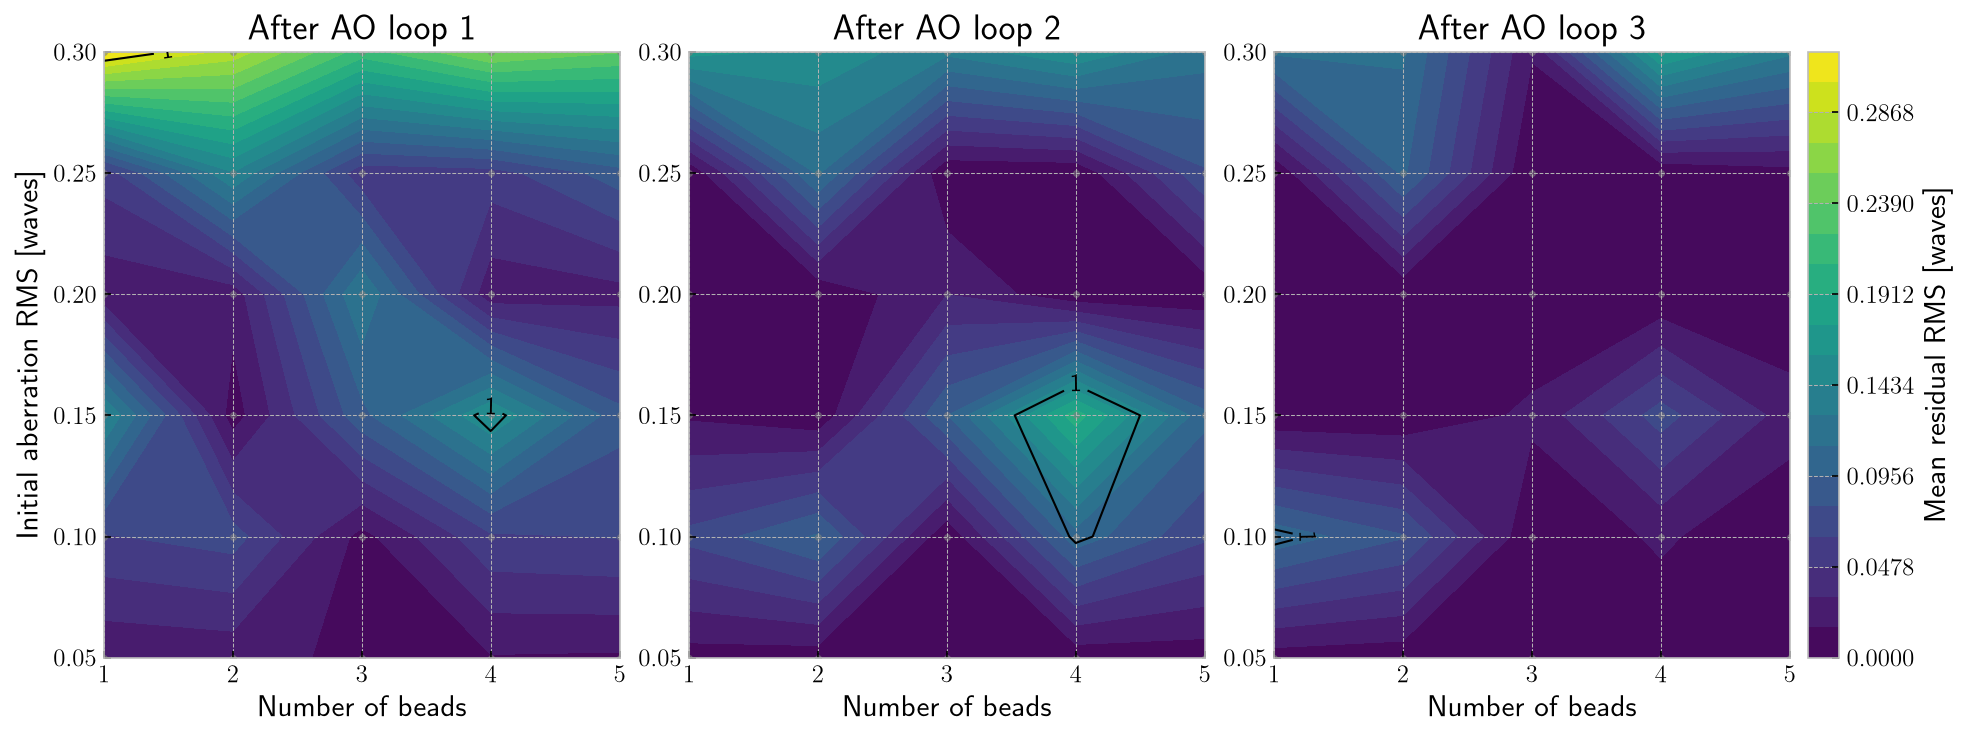

In [32]:
# Filled contours styled like the rho maps in lambda_test.ipynb.
# Black contour: residual RMS equals initial RMS (no net improvement).
fig = plt.figure(figsize=(13, 4.8), dpi=150, layout="constrained")
layout = fig.add_gridspec(1, NUM_AO_LOOPS+1, width_ratios=[1]*NUM_AO_LOOPS+[0.06])
bead_order = np.argsort(BEAD_COUNTS)
rms_order = np.argsort(INITIAL_RMS_VALUES)
contour_x = np.asarray(BEAD_COUNTS)[bead_order]
contour_y = np.asarray(INITIAL_RMS_VALUES)[rms_order]
sampled_x, sampled_y = np.meshgrid(contour_x, contour_y)
contour_values = mean_residual_rms[rms_order][:, bead_order, :]
color_max = max(float(np.nanmax(contour_values)), np.finfo(float).eps)
levels = np.linspace(0, color_max, 21)
norm = plt.Normalize(0, color_max)
has_contour_grid = len(contour_x) >= 2 and len(contour_y) >= 2
if not has_contour_grid:
    print("Contours need at least two bead-count and two RMS values; displaying sampled points.")
for loop in range(NUM_AO_LOOPS):
    ax = fig.add_subplot(layout[0, loop])
    values = contour_values[:, :, loop]
    if has_contour_grid:
        im = ax.contourf(contour_x, contour_y, values,
                         levels=levels, norm=norm, cmap="viridis")
        ratio = values/contour_y[:, None]
        if np.nanmin(ratio) < 1 < np.nanmax(ratio):
            boundary = ax.contour(contour_x, contour_y, ratio,
                                  levels=[1], colors="black", linewidths=1)
            ax.clabel(boundary, fmt="%g")
        ax.scatter(sampled_x.ravel(), sampled_y.ravel(), s=8, c="gray", alpha=0.5)
    else:
        im = ax.scatter(sampled_x.ravel(), sampled_y.ravel(), c=values.ravel(),
                        s=80, norm=norm, cmap="viridis")
        ax.set_xticks(contour_x)
        ax.set_yticks(contour_y)
    ax.set_xticks(BEAD_COUNTS)
    ax.set_xlabel("Number of beads")
    ax.set_ylabel("Initial aberration RMS [waves]" if loop == 0 else "")
    ax.set_title(f"After AO loop {loop+1}")
fig.colorbar(im, cax=fig.add_subplot(layout[0, -1]), label="Mean residual RMS [waves]")
fig.savefig(FIGURES_DIR / "bead_count_ao_loop_contours.png", bbox_inches="tight")
plt.show()


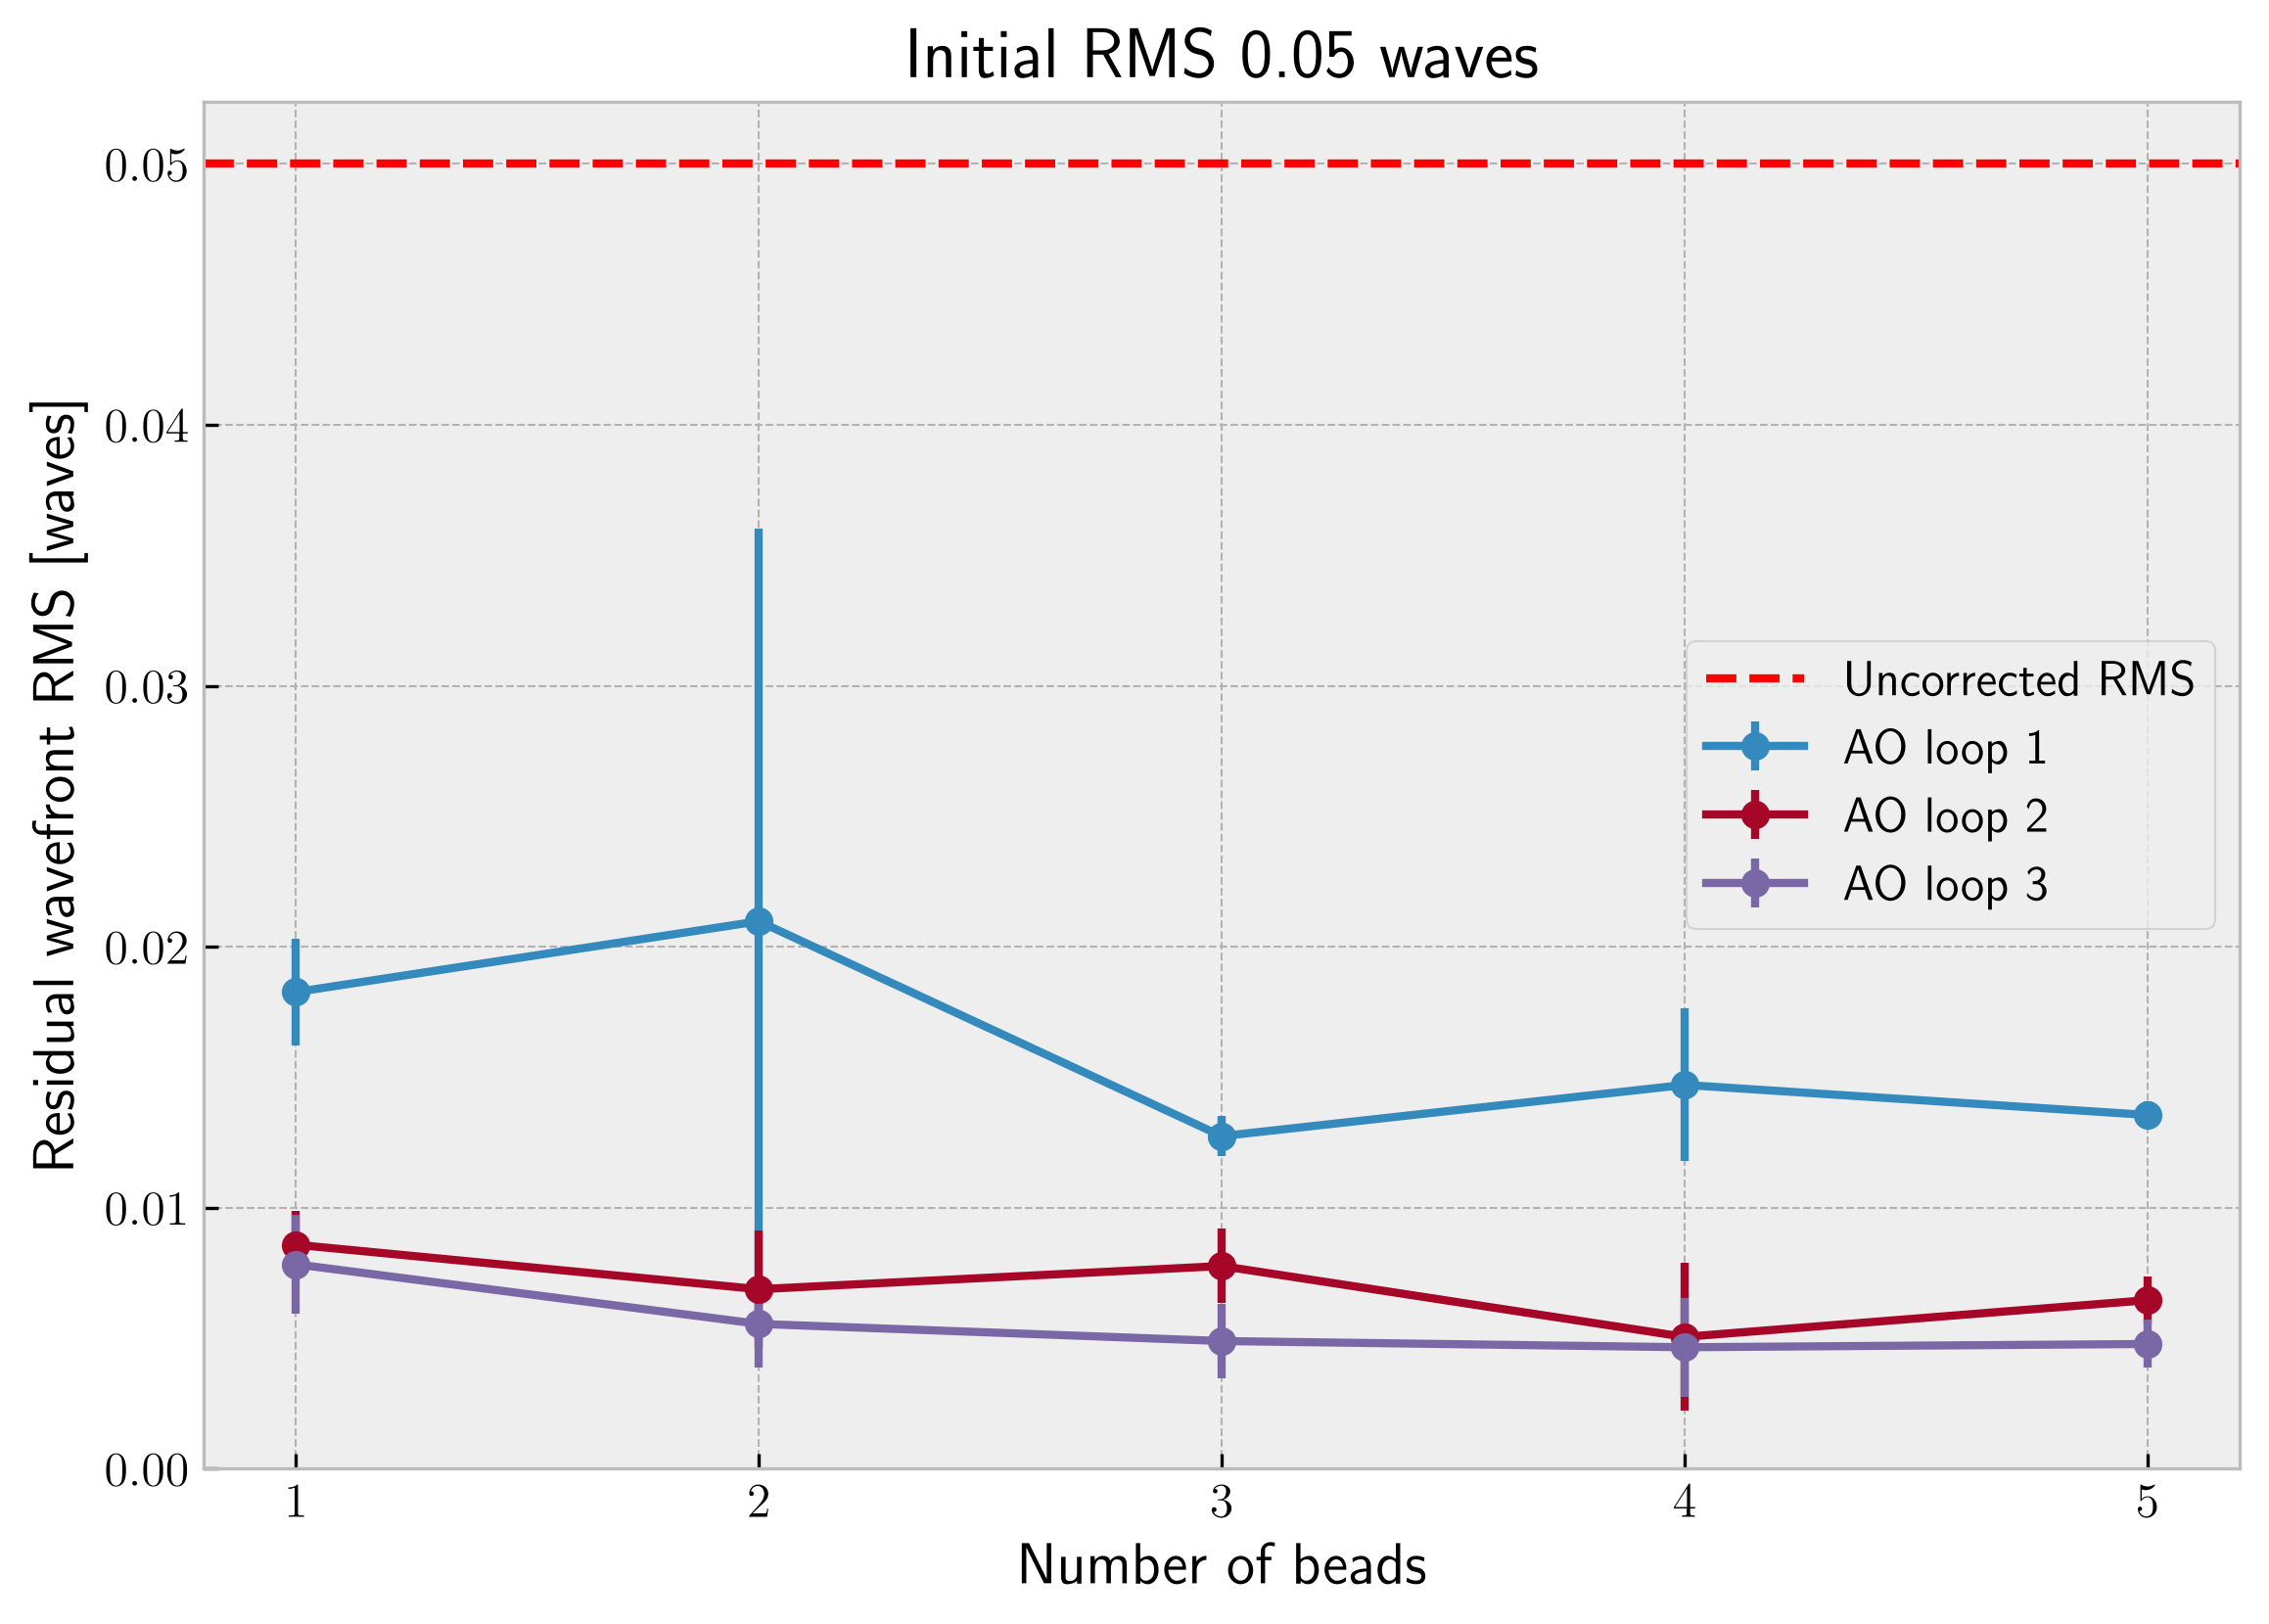

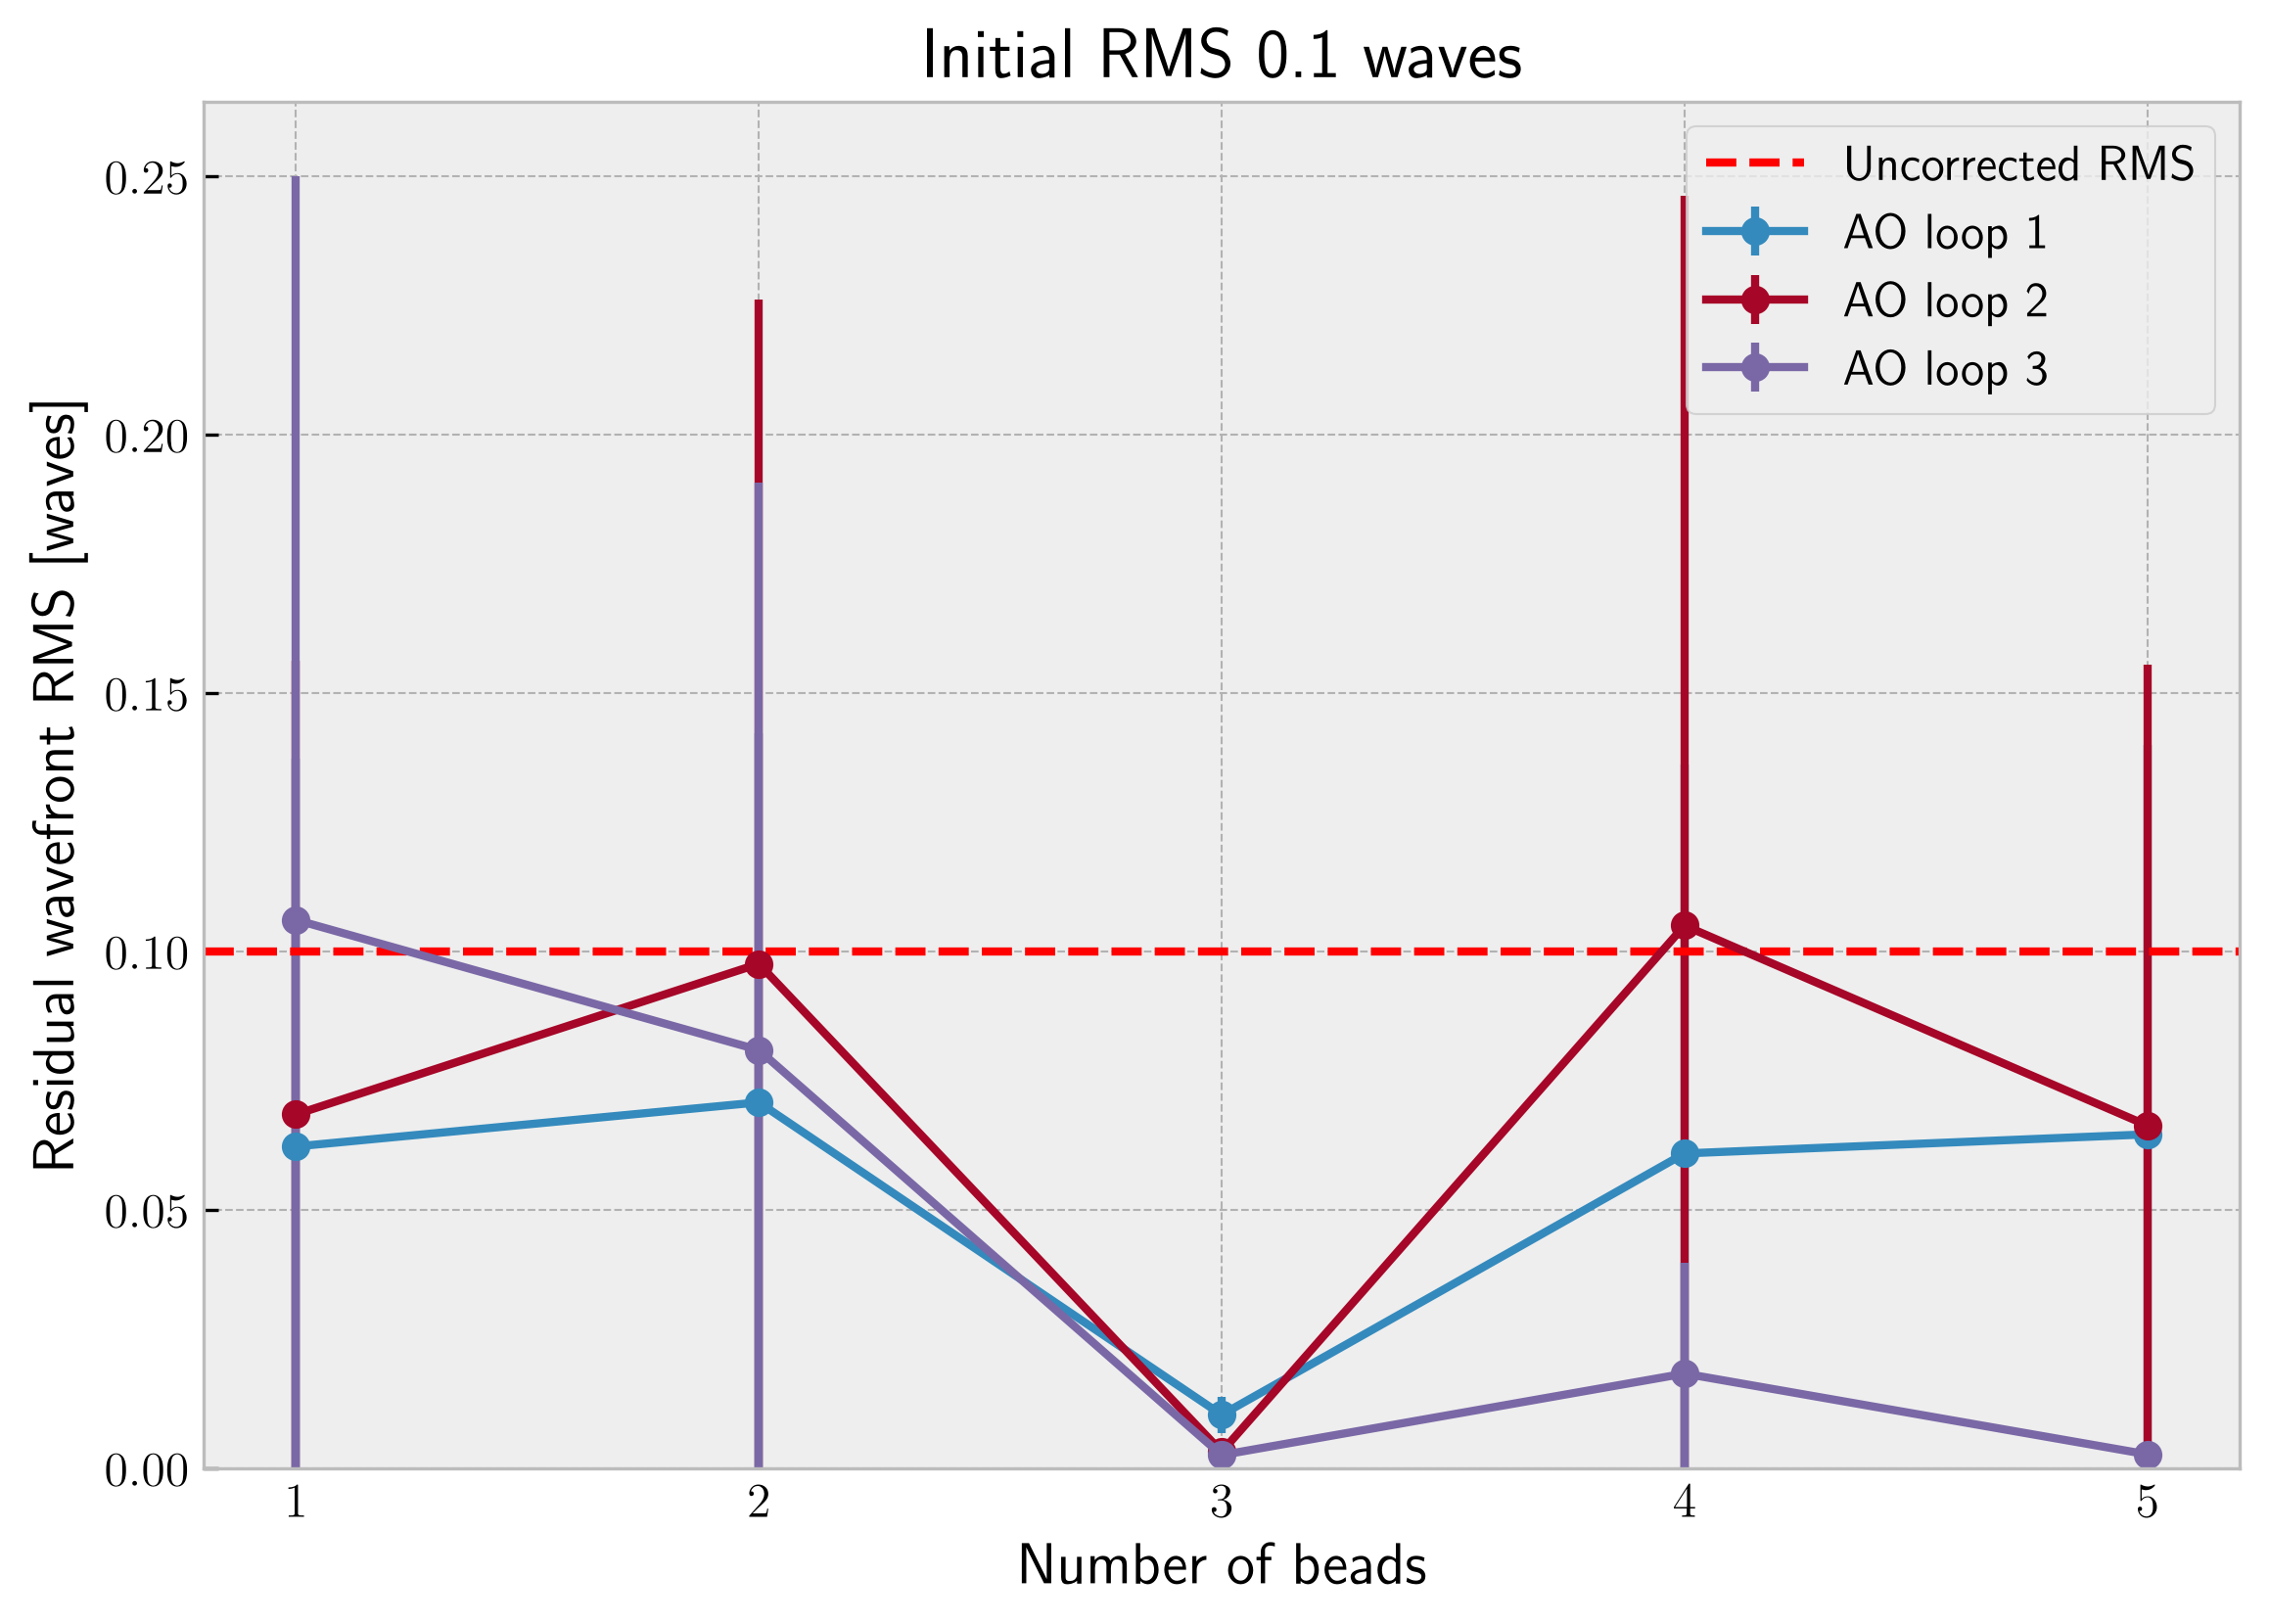

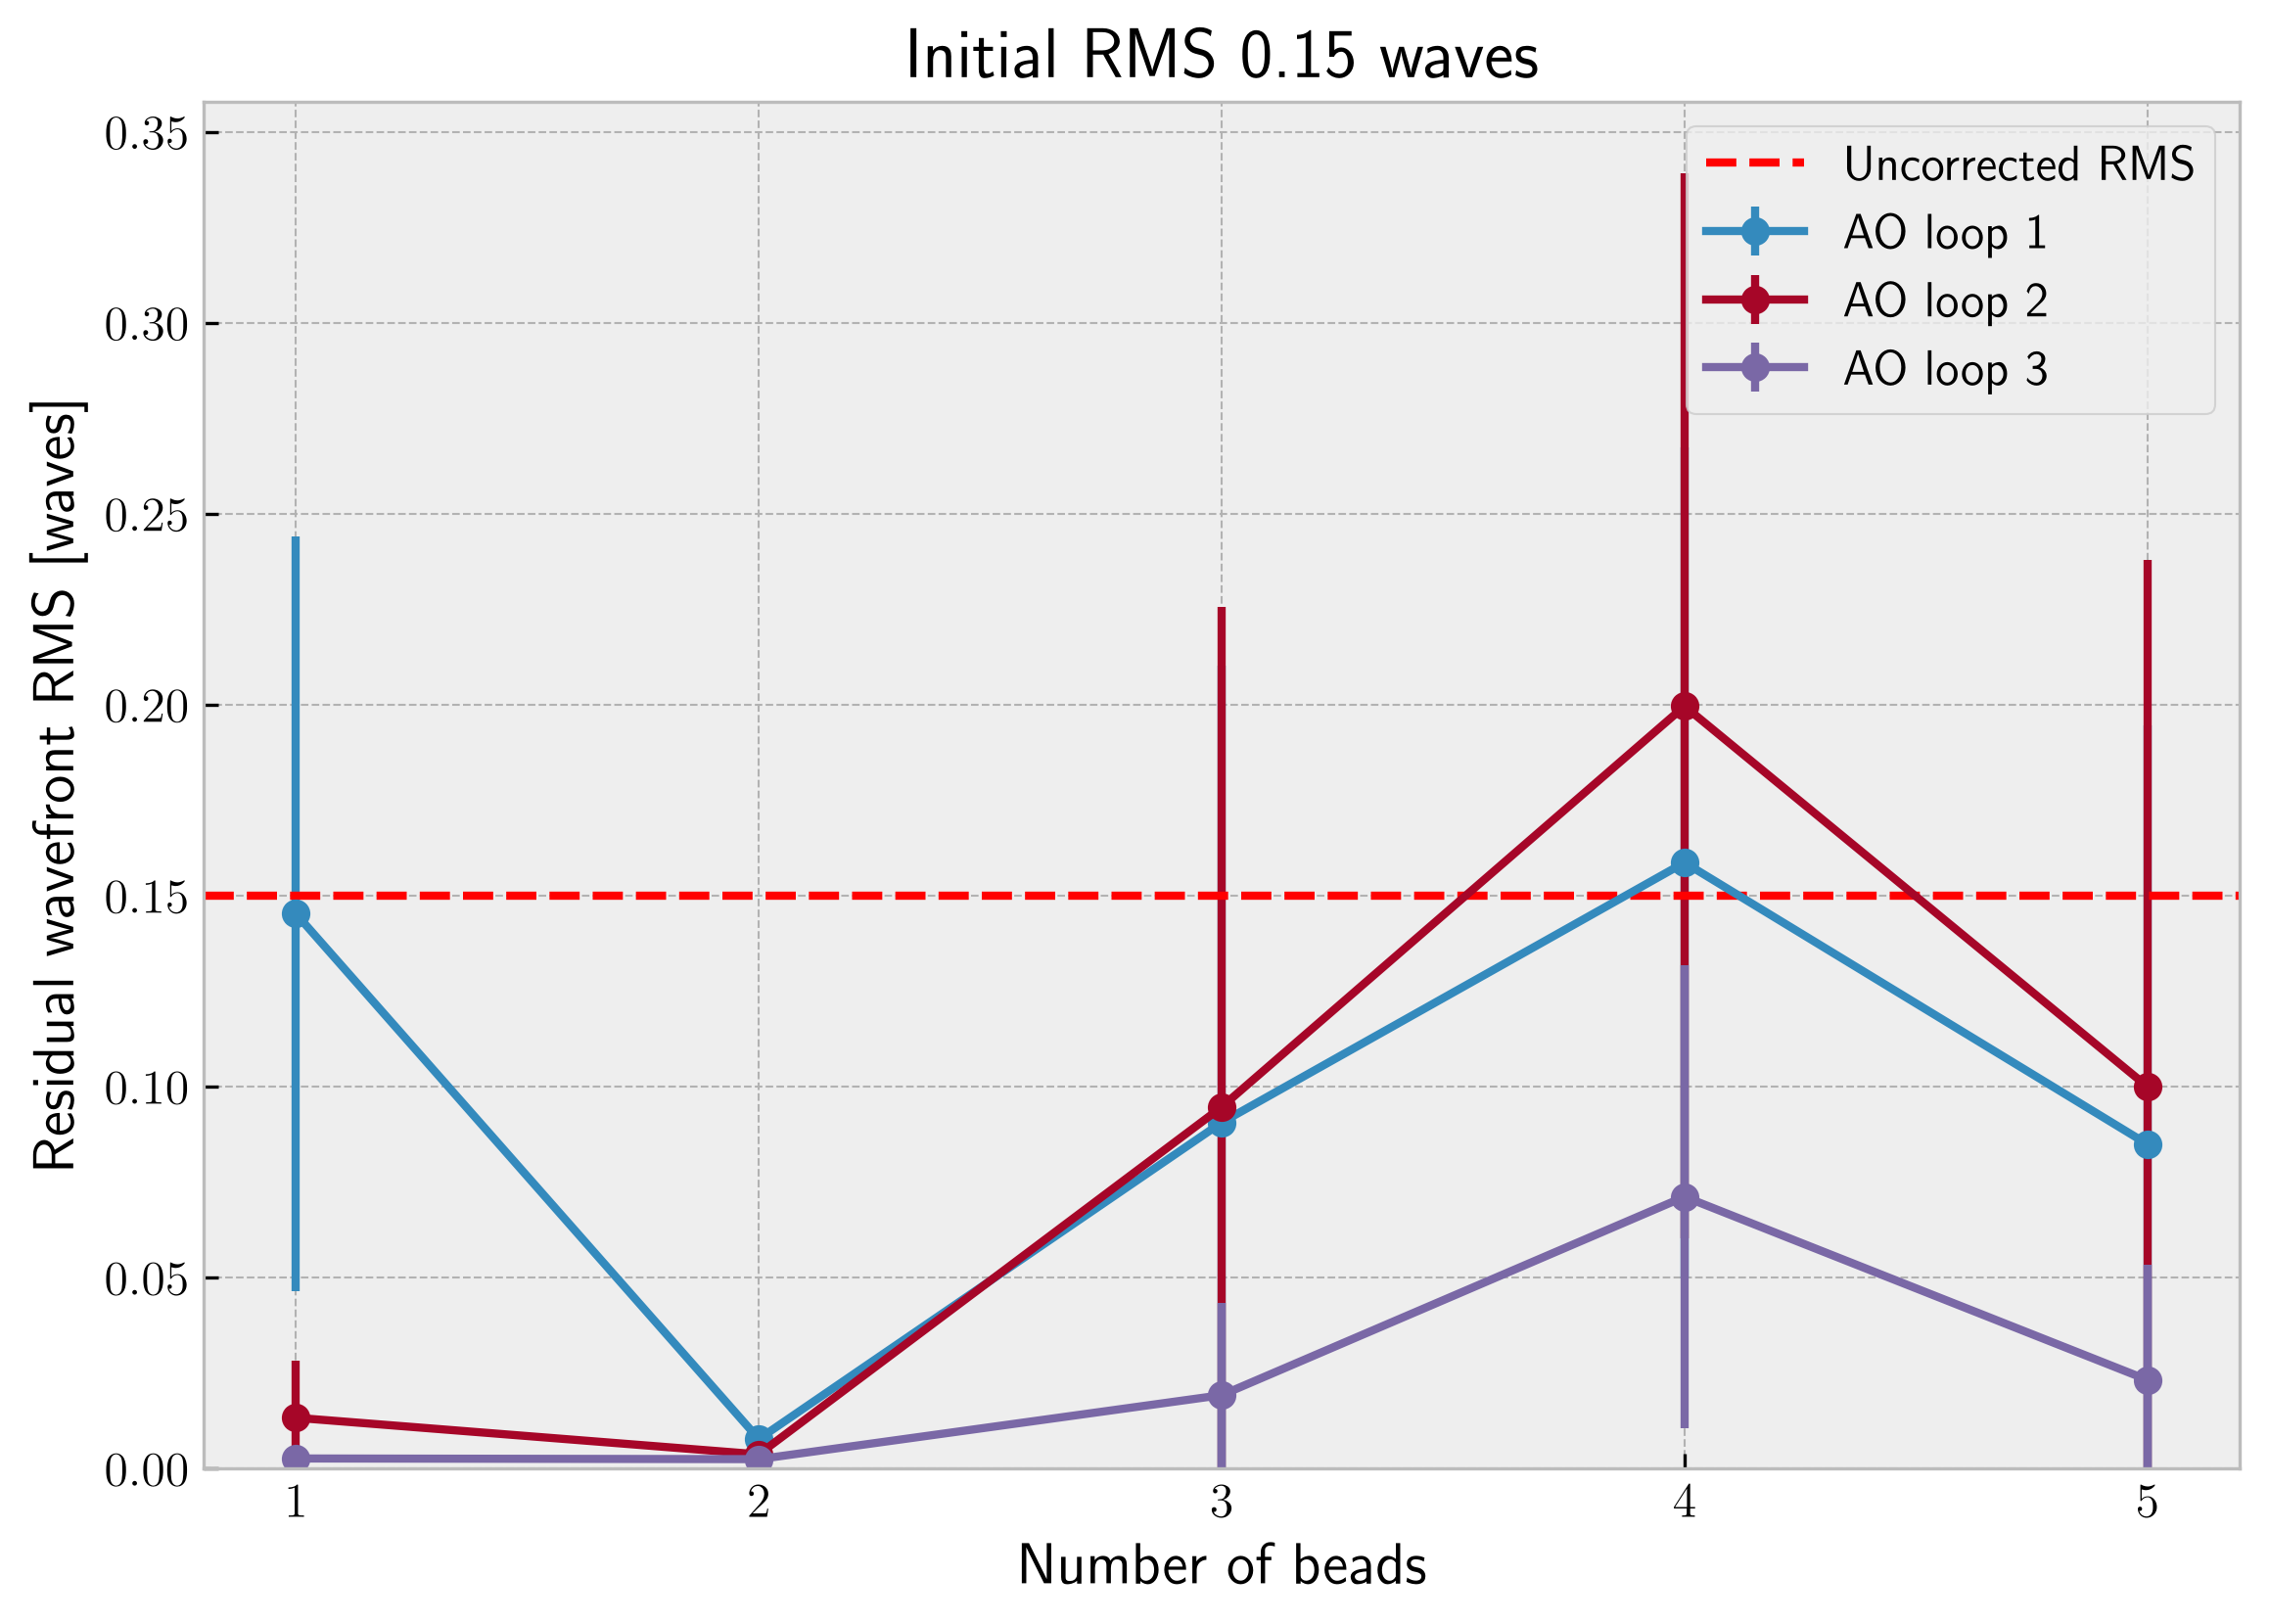

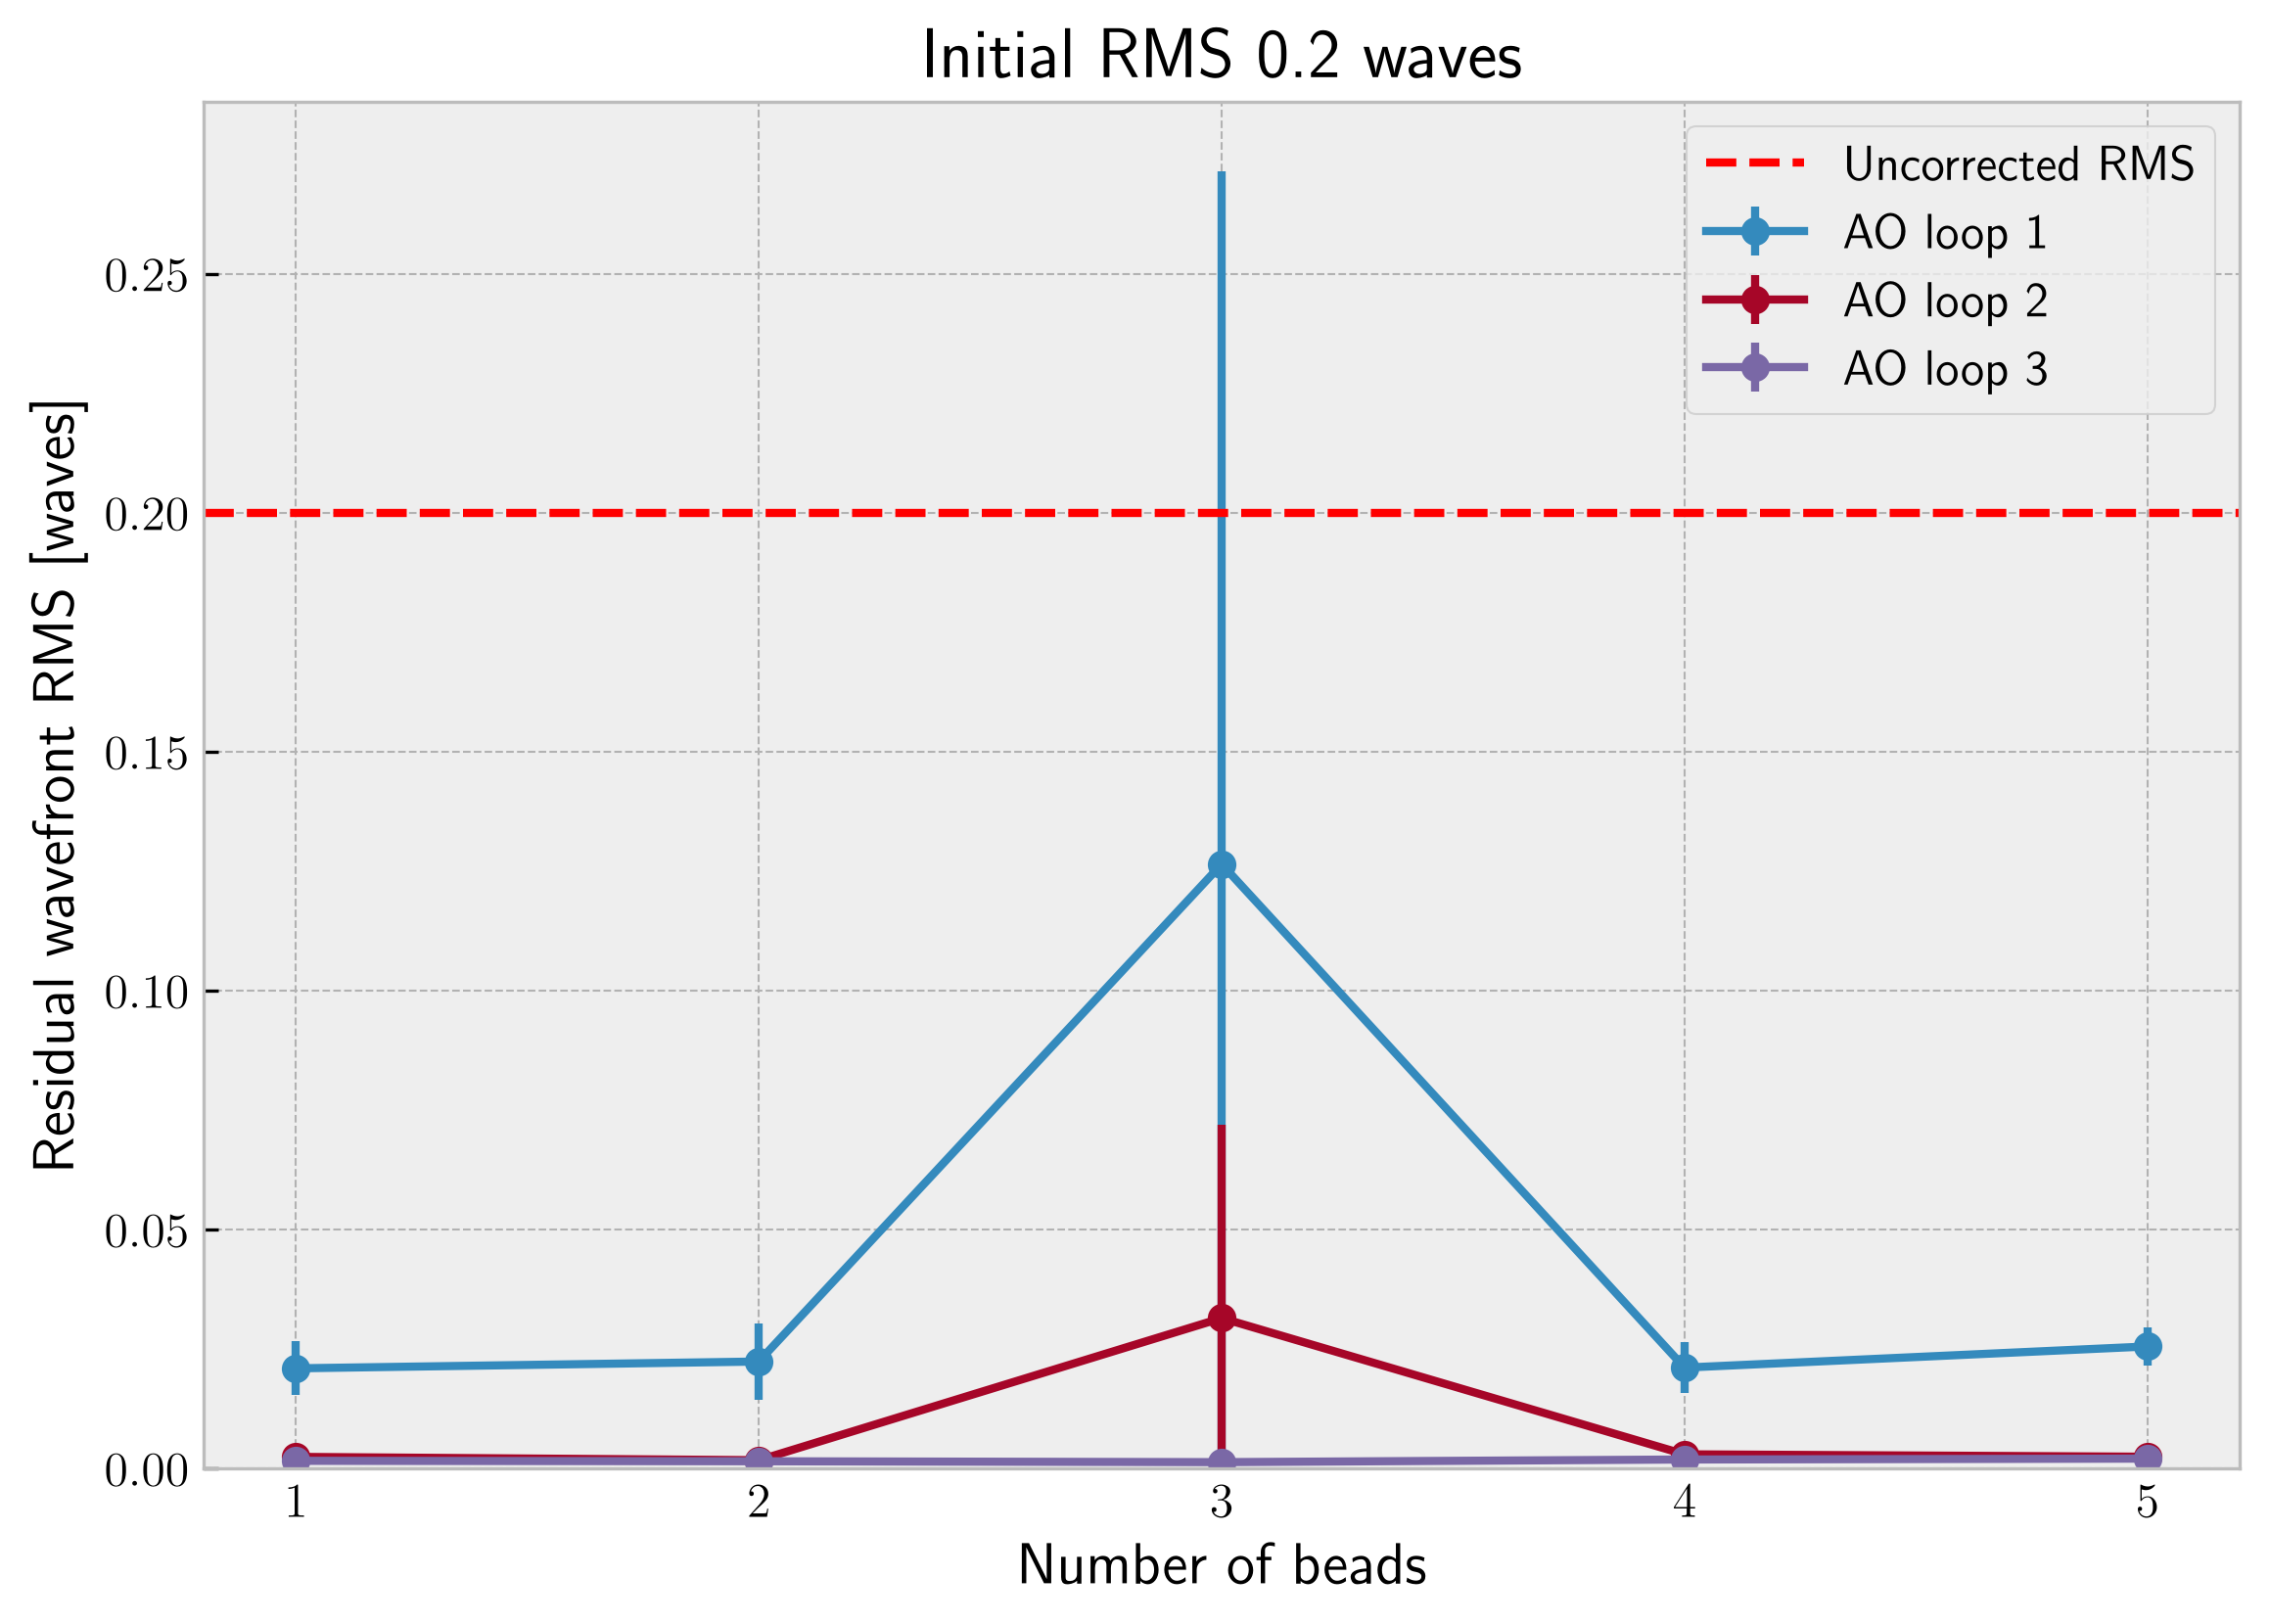

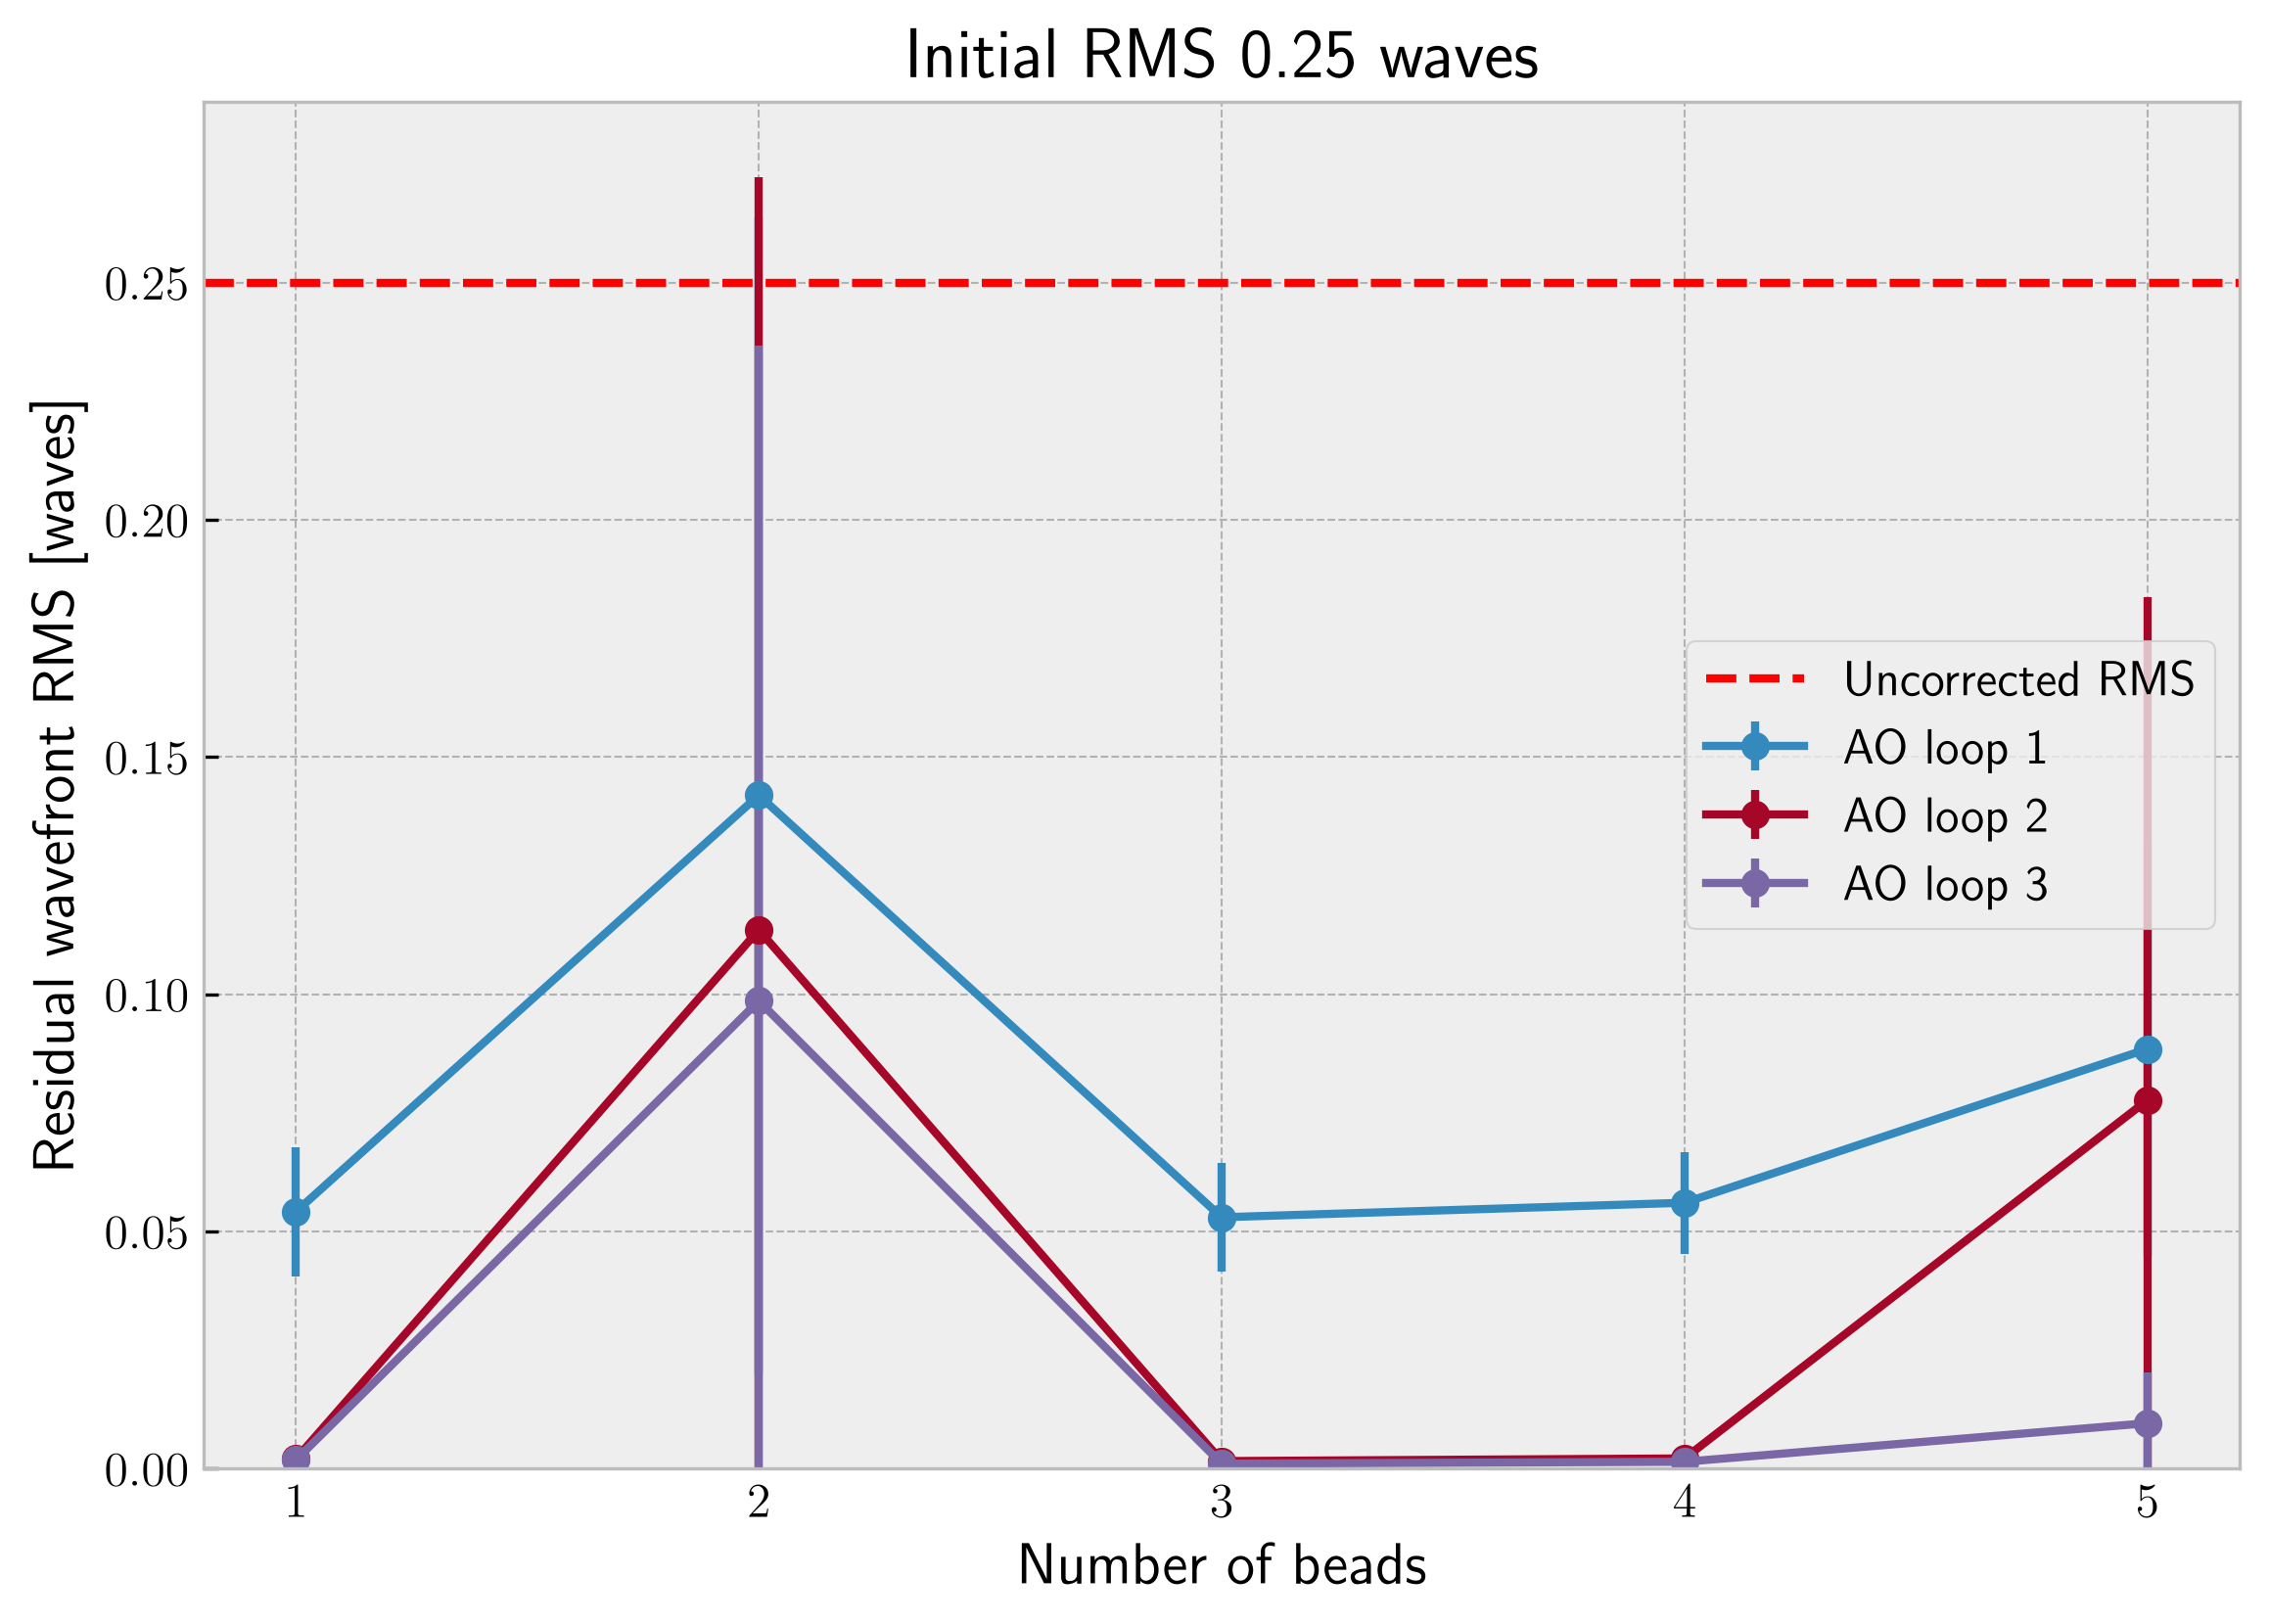

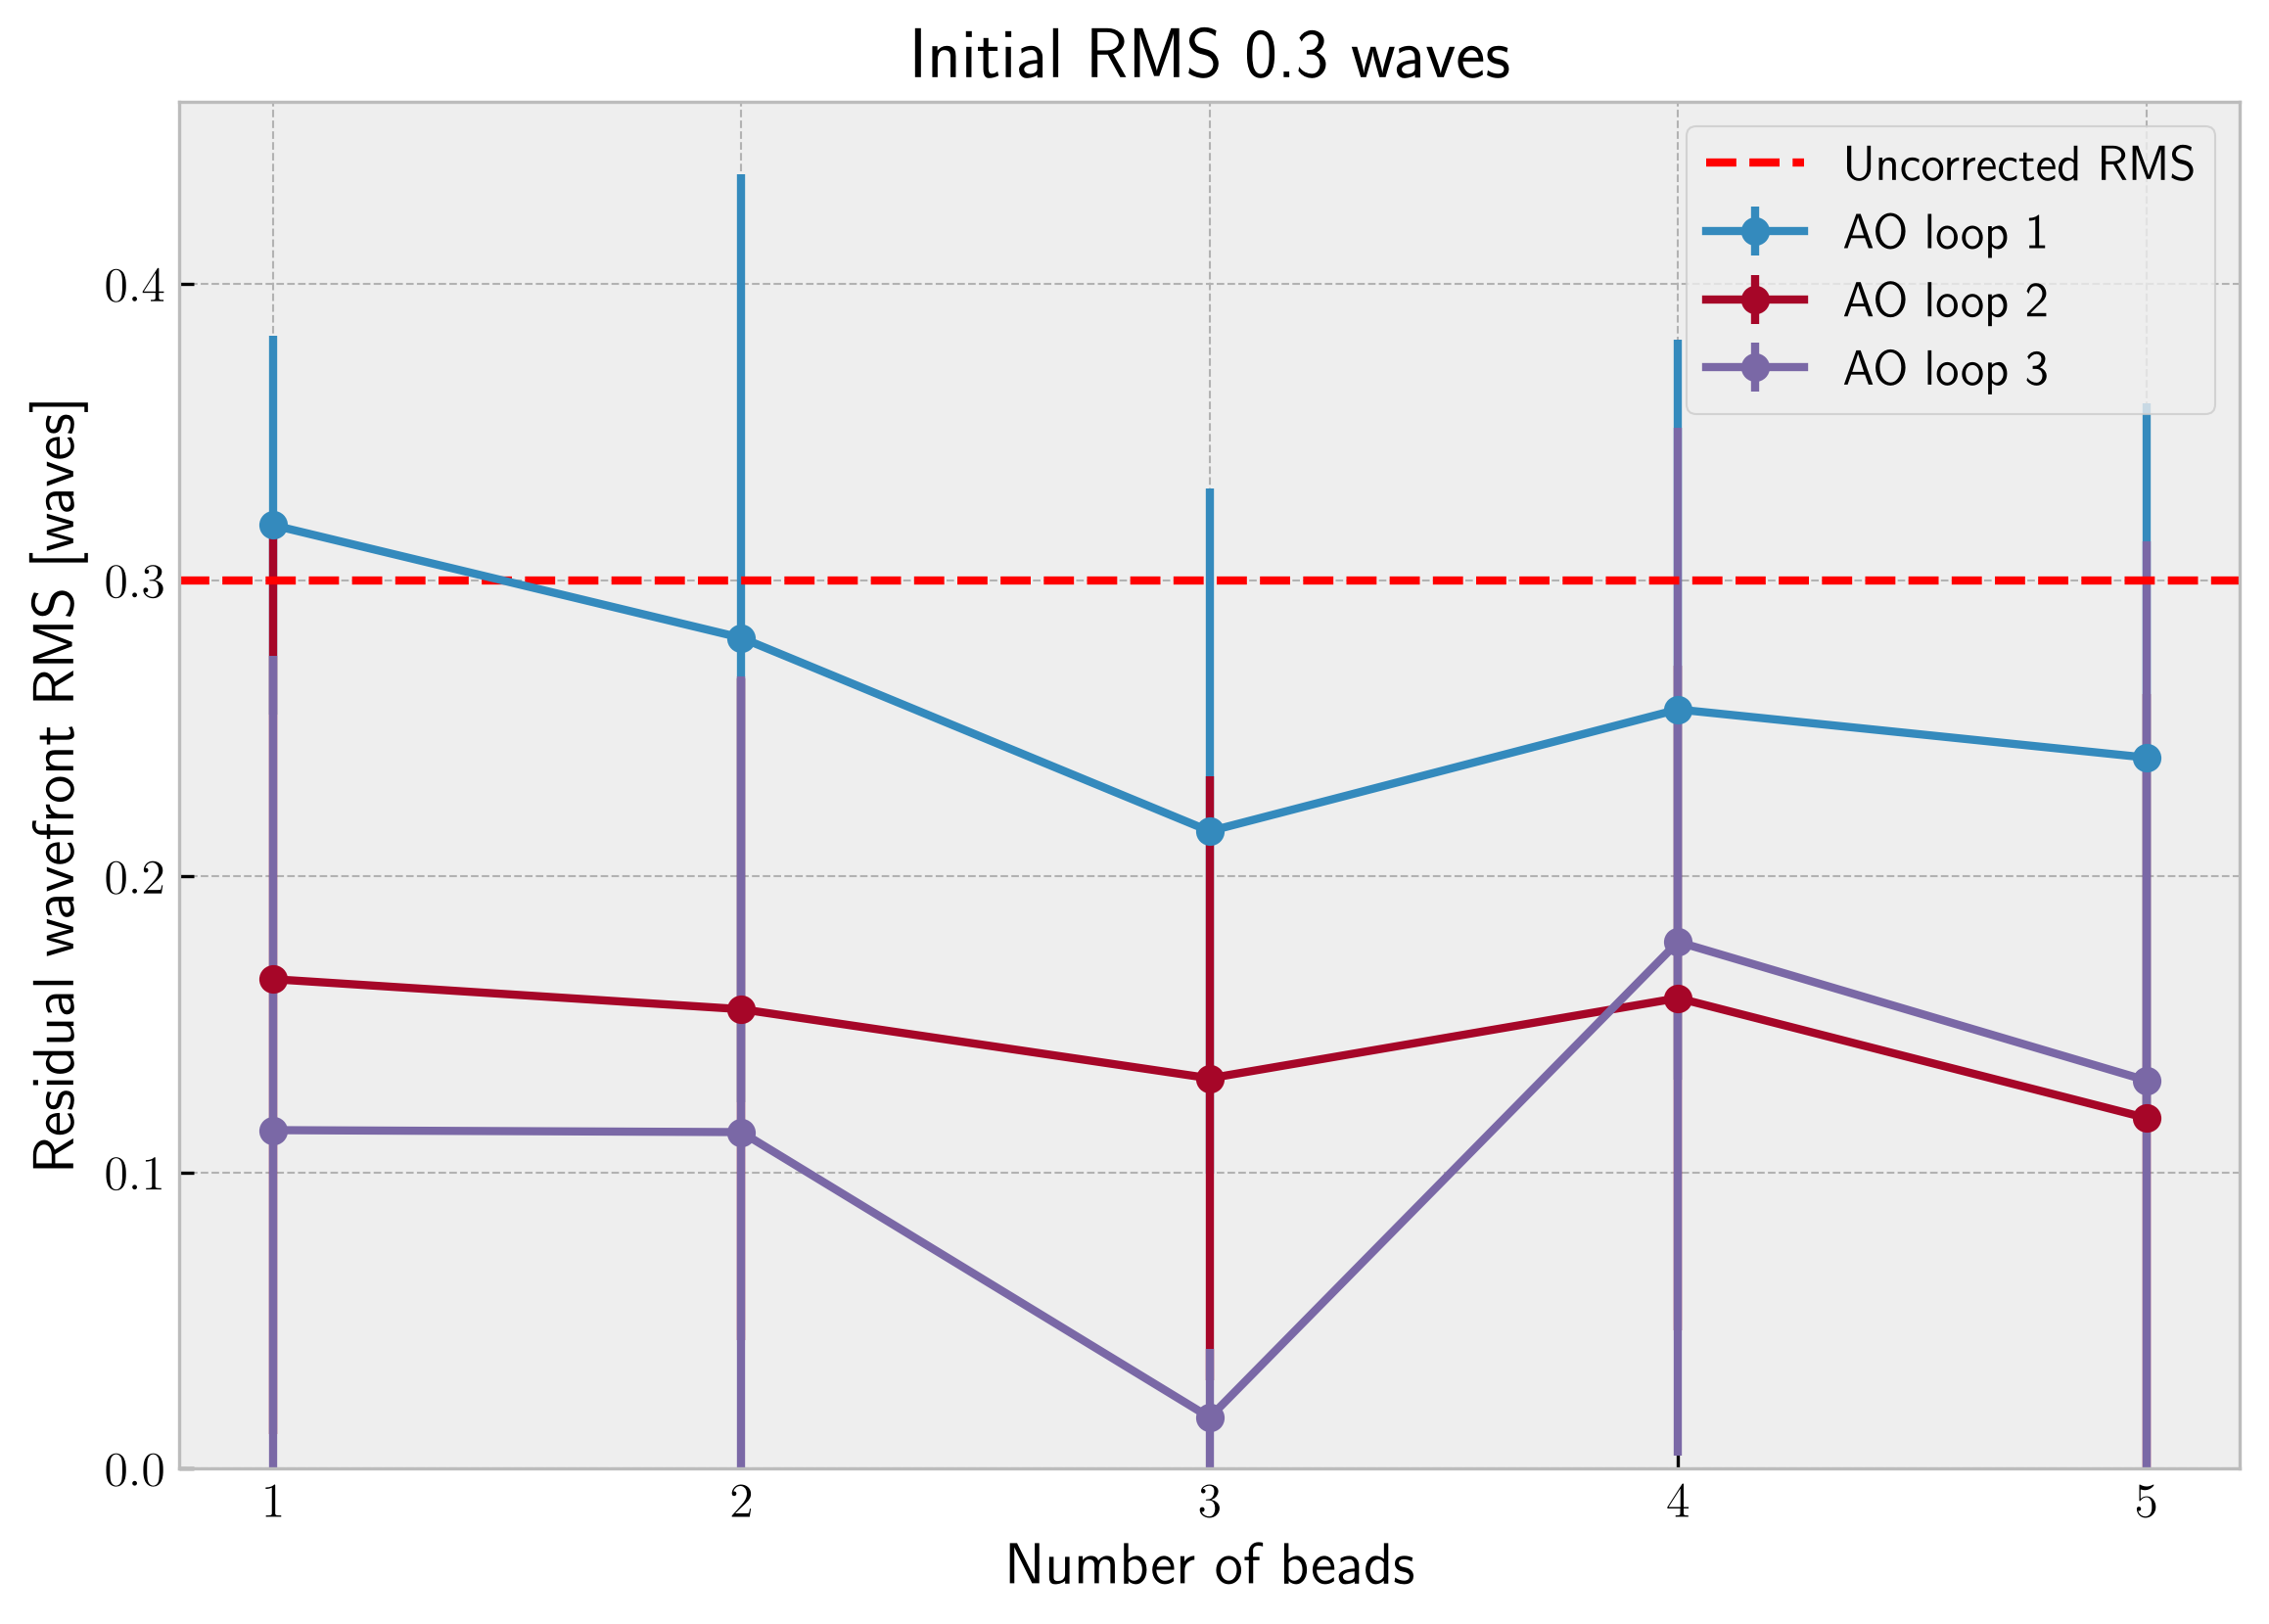

Loop 1: optimizer converged in 89/90 runs; mean residual/initial RMS=0.486
Loop 2: optimizer converged in 80/90 runs; mean residual/initial RMS=0.343
Loop 3: optimizer converged in 76/90 runs; mean residual/initial RMS=0.193


In [33]:
# Relative residual: below 1 means improvement, above 1 means degradation.
relative_residual = mean_residual_rms/INITIAL_RMS_VALUES[:, None, None]
for rms_index, initial_rms in enumerate(INITIAL_RMS_VALUES):
    fig, ax = plt.subplots(layout="constrained")
    #NUM_AO_LOOPS
    for loop in range(NUM_AO_LOOPS):
        mean = mean_residual_rms[rms_index, :, loop]
        std = std_residual_rms[rms_index, :, loop]
        ax.errorbar(BEAD_COUNTS, mean, std, marker="o", label=f"AO loop {loop+1}")
        #if NUM_TRIALS > 1:
            #ax.fill_between(BEAD_COUNTS, np.maximum(0, mean-std), mean+std, alpha=.15)
    ax.axhline(initial_rms, c="red", ls="dashed", label="Uncorrected RMS")
    ax.set_xlabel("Number of beads")
    ax.set_ylabel("Residual wavefront RMS [waves]")
    ax.set_title(f"Initial RMS {initial_rms:g} waves")
    ax.set_ylim(bottom=0)
    ax.set_xticks(BEAD_COUNTS)
    ax.legend()
    plt.savefig(FIGURES_DIR / f"bead_count_ao_loop_init_rms_{initial_rms}_new.png")
    plt.show()
for loop in range(NUM_AO_LOOPS):
    print(f"Loop {loop+1}: optimizer converged in {optimizer_success[..., loop].sum()}/"
          f"{optimizer_success[..., loop].size} runs; "
          f"mean residual/initial RMS={relative_residual[..., loop].mean():.3f}")

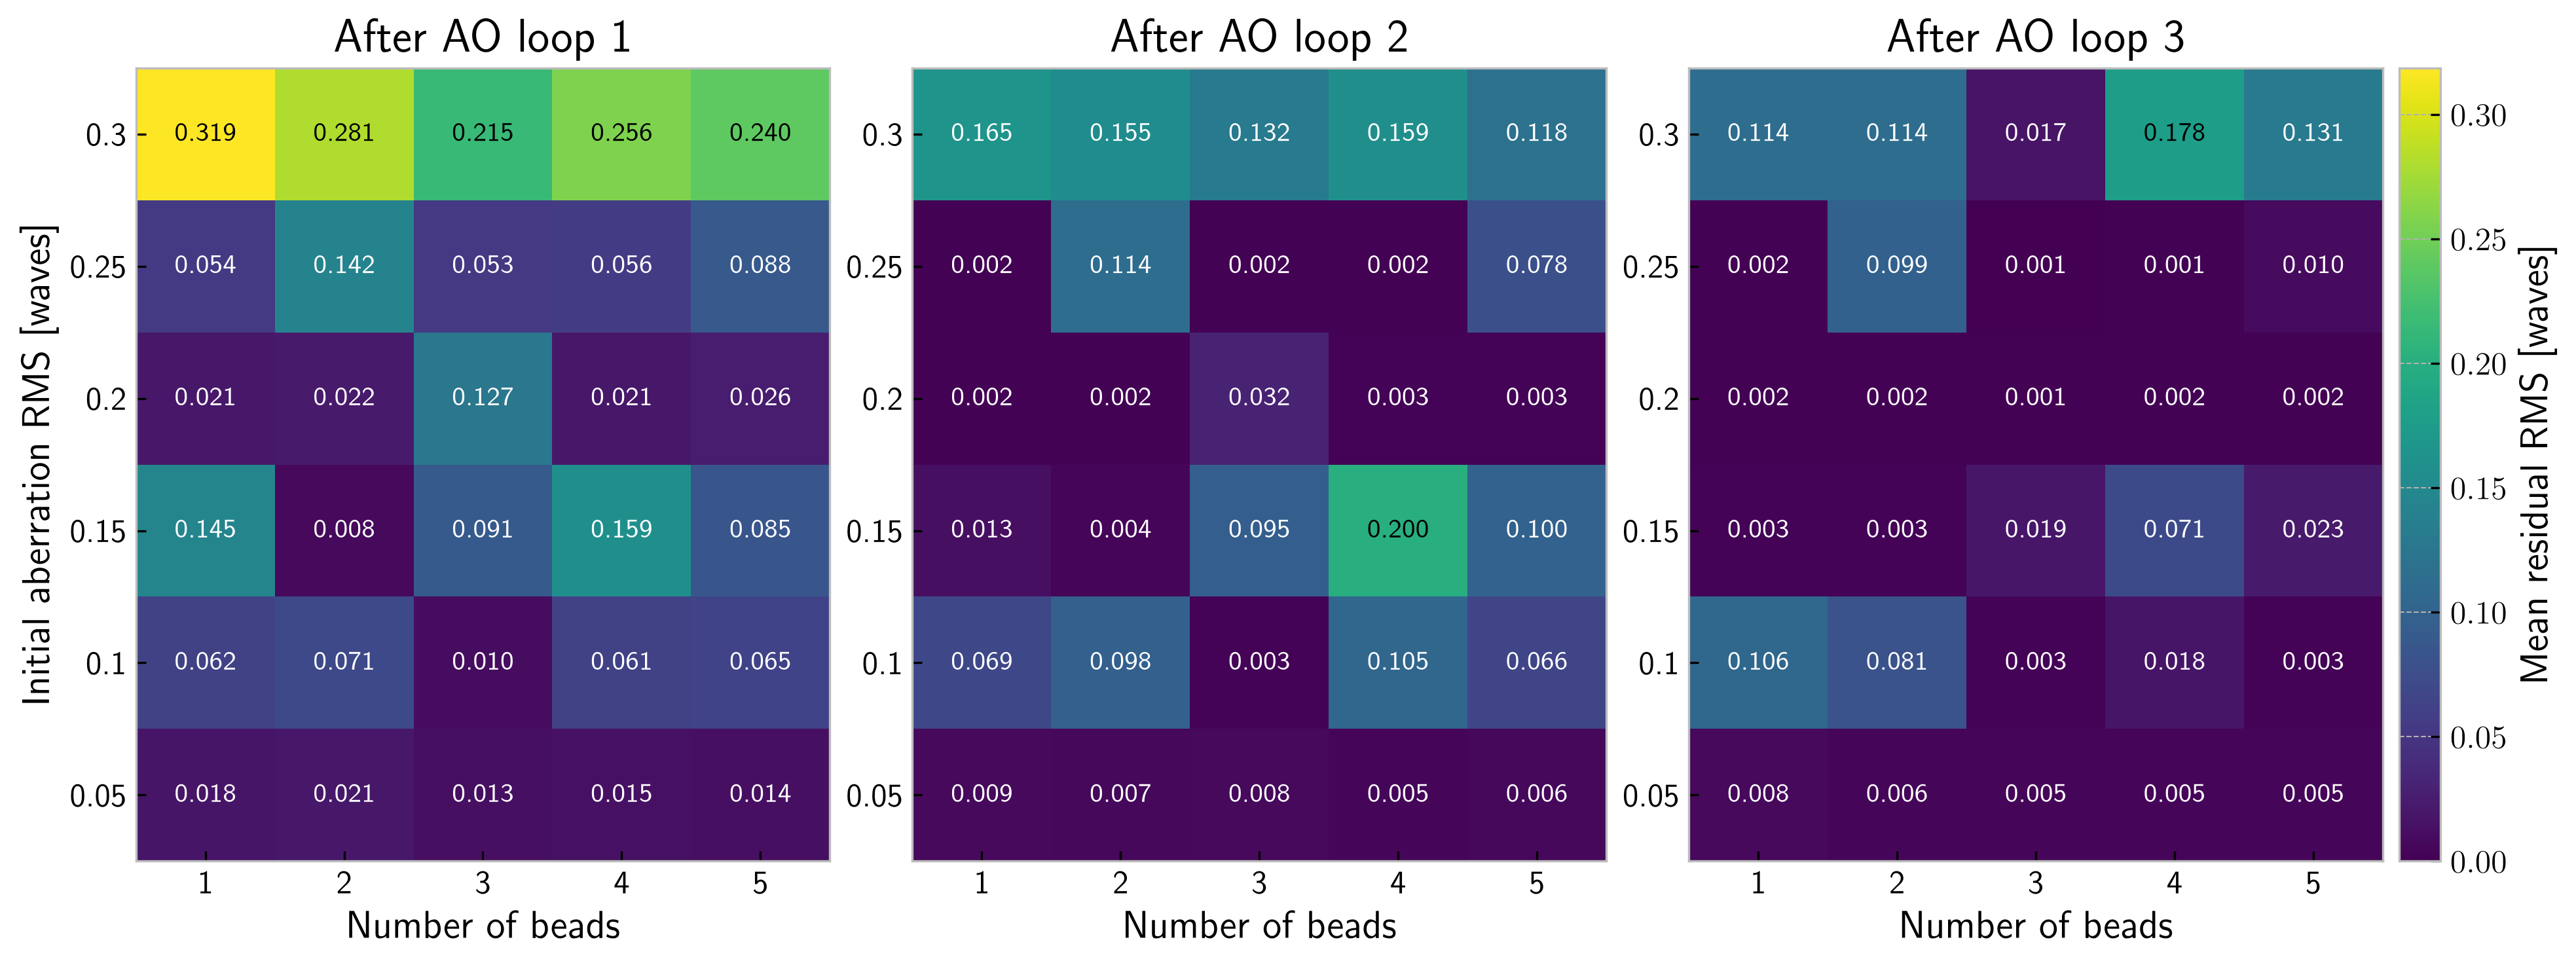

In [34]:
#Common color scale for direct comparison after loops 1, 2, and 3.
fig = plt.figure(figsize=(13, 4.8), layout="constrained")
layout = fig.add_gridspec(1, NUM_AO_LOOPS+1, width_ratios=[1]*NUM_AO_LOOPS+[0.06])
norm = plt.Normalize(0, max(float(mean_residual_rms.max()), np.finfo(float).tiny))
for loop in range(NUM_AO_LOOPS):
    ax = fig.add_subplot(layout[0, loop])
    im = ax.imshow(mean_residual_rms[:, :, loop], origin="lower", aspect="auto", norm=norm, cmap="viridis")
    ax.set_xticks(np.arange(len(BEAD_COUNTS)), [f"{v:g}" for v in BEAD_COUNTS])
    ax.set_yticks(np.arange(len(INITIAL_RMS_VALUES)), [f"{v:g}" for v in INITIAL_RMS_VALUES])
    ax.set_xlabel("Number of beads")
    ax.set_ylabel("Initial aberration RMS [waves]" if loop == 0 else "")
    ax.set_title(f"After AO loop {loop+1}")
    ax.grid(False)
    for ri in range(len(INITIAL_RMS_VALUES)):
        for si in range(len(BEAD_COUNTS)):
            value = mean_residual_rms[ri, si, loop]
            ax.text(si, ri, f"{value:.3f}", ha="center", va="center",
                    color="white" if norm(value) < .55 else "black", fontsize=10)
fig.colorbar(im, cax=fig.add_subplot(layout[0, -1]), label="Mean residual RMS [waves]")
plt.savefig(FIGURES_DIR / "bead_count_ao_loop_heatmaps.png")
plt.show()